In [16]:

%matplotlib inline
%load_ext autoreload
%autoreload 2

import gc

import joblib
import pandas as pd
import torch
from imblearn.pipeline import Pipeline
from numpy import set_printoptions
from sklearn import set_config
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder

from csm500_project.constant import RAW_TRAIN_DATASET_X_PATH, RAW_TRAIN_DATASET_Y_PATH, INFERRED_TARGET_FIELD, \
    RAW_TEST_DATASET_X_PATH, RAW_TEST_DATASET_Y_PATH, BAGGING_CLASSIFIER_KNEIGHBOURS_DUMP
from csm500_project.continuous_data_analysis import CONTINUOUS_DATA_FIELDS
from csm500_project.discrete_data_analysis import DROPPED_CATEGORIES, HIGH_CARDINALITY_ENCODED_CATEGORIES, \
    LOW_CARDINALITY_ENCODED_CATEGORIES, X_ORDINAL_ENCODED_CATEGORIES
from csm500_project.ensemble_model_development import run_kneighbours_bagging_classifier_pipeline, \
    run_random_forest_pipeline, run_adaboost_decision_tree_pipeline
from csm500_project.model_development import run_model_pipeline
from csm500_project.model_pipeline import get_build_model_pipeline
from csm500_project.shap_analysis import run_shap_analysis, run_shap_inconsistency_analysis
from csm500_project.target_distribution import plot_target_distribution
from csm500_project.util import split_primary_physical_datasets

set_config(display="diagram", transform_output="pandas")
set_printoptions(precision=2, linewidth=250)

x_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_X_PATH)
y_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_Y_PATH)
x_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_X_PATH)
y_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_Y_PATH)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


X-Train Null Values:
Organisation Entity                                   0
Description                                           0
Development Classification                            0
Entry Date Year Of Transfer                           0
Entry Date Quarter Of Transfer                        0
Decision Date Year Of Transfer                        0
Decision Date Quarter Of Transfer                     0
LSOA Code                                             0
Council Code                                          0
IMD Rank                                              0
IMD Decile                                            0
In Conservation Area                                  0
Listing Grade                                         0
Geohazards Collapsible Deposits Susceptibility        0
Geohazards Compressible Ground Susceptibility         0
Geohazards Landslides Susceptibility                  0
Geohazards Running Sand Susceptibility                0
Geohazards Shrink Swell Sus

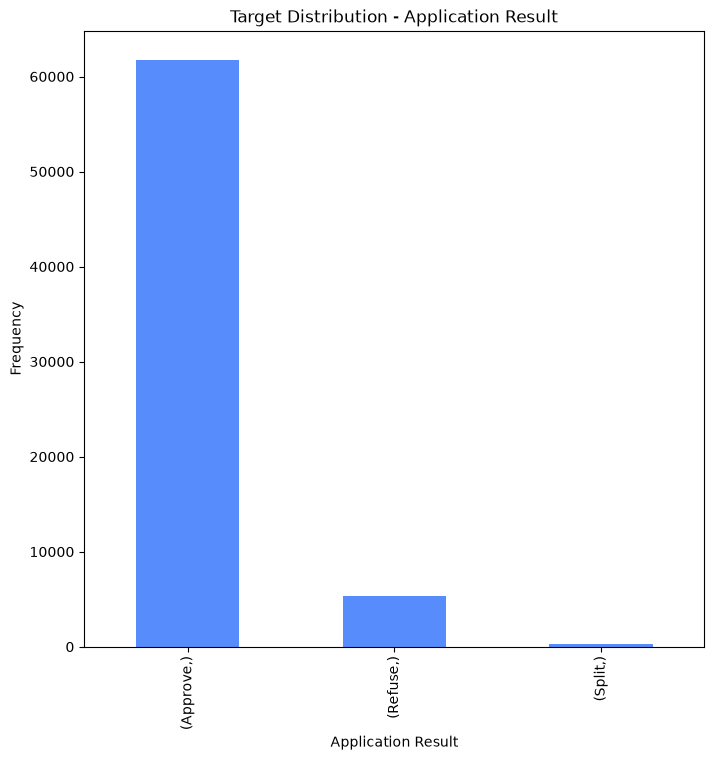

In [2]:
plot_target_distribution(x_train, y_train, "Target Distribution - Application Result")

In [3]:
target_label_encoder: LabelEncoder = LabelEncoder()


def _prepare_target(y: pd.DataFrame) -> None:
    y[INFERRED_TARGET_FIELD] = target_label_encoder.fit_transform(y[INFERRED_TARGET_FIELD])


train_datasets = split_primary_physical_datasets(x_train, y_train, False)
test_datasets = split_primary_physical_datasets(x_test, y_test, False)

primary_x_train: pd.DataFrame = train_datasets['x_primary']
physical_x_train: pd.DataFrame = train_datasets['x_physical']
primary_y_train: pd.DataFrame = train_datasets['y_primary']
physical_y_train: pd.DataFrame = train_datasets['y_physical']

_prepare_target(primary_y_train)
_prepare_target(physical_y_train)

primary_x_test: pd.DataFrame = test_datasets['x_primary']
physical_x_test: pd.DataFrame = test_datasets['x_physical']
primary_y_test: pd.DataFrame = test_datasets['y_primary']
physical_y_test: pd.DataFrame = test_datasets['y_physical']

_prepare_target(primary_y_test)
_prepare_target(physical_y_test)

print("Loaded datasets from Cache.")

Loaded datasets from Cache.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7207.43it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Log Regression Test Cross Val Accuracy: 0.4538 (0.0025)
Log Regression Test Cross Val Balanced Accuracy: 0.6204 (0.0192)
Log Regression Test Cross Val F1 Macro: 0.2886 (0.0013)
Log Regression Test Cross Val ROC AUC: 0.7394 (0.0047)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6211.19it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.41      0.57     11415
           1       0.15      0.64      0.24      1031
           2       0.01      0.88      0.02        42

    accuracy                           0.43     12488
   macro avg       0.37      0.64      0.28     12488
weighted avg       0.88      0.43      0.54     12488

Confusion Matrix
[[4660 3804 2951]
 [ 245  656  130]
 [   1    4   37]]


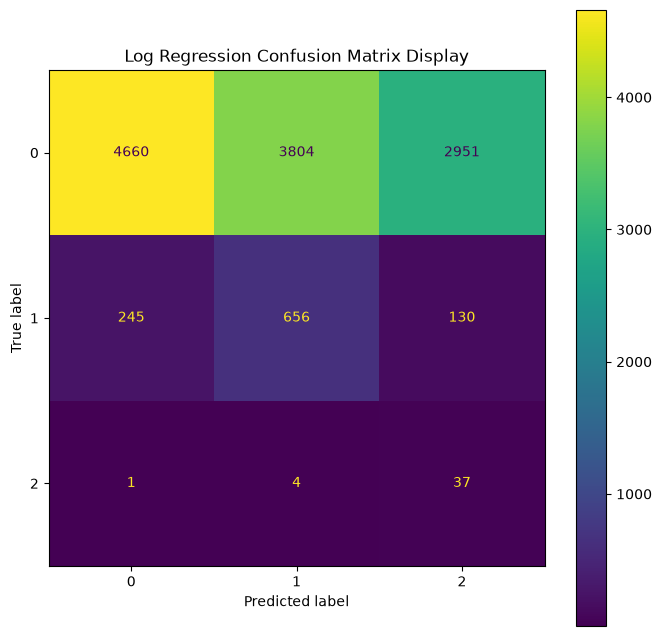

0 [0.81 0.25 0.24 ... 0.34 0.22 0.13]
1 [0.15 0.07 0.1  ... 0.6  0.77 0.82]
2 [0.04 0.67 0.66 ... 0.06 0.01 0.05]


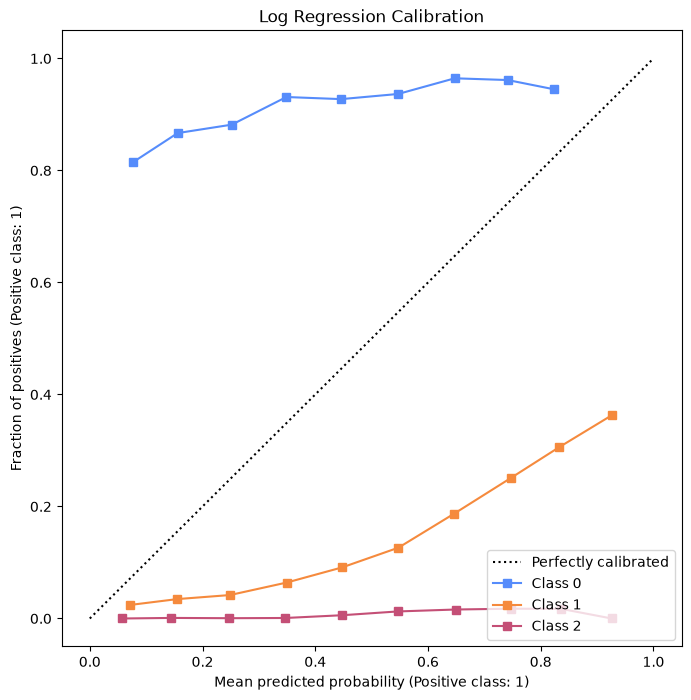

0 [0.81 0.25 0.24 ... 0.34 0.22 0.13]
1 [0.15 0.07 0.1  ... 0.6  0.77 0.82]
2 [0.04 0.67 0.66 ... 0.06 0.01 0.05]


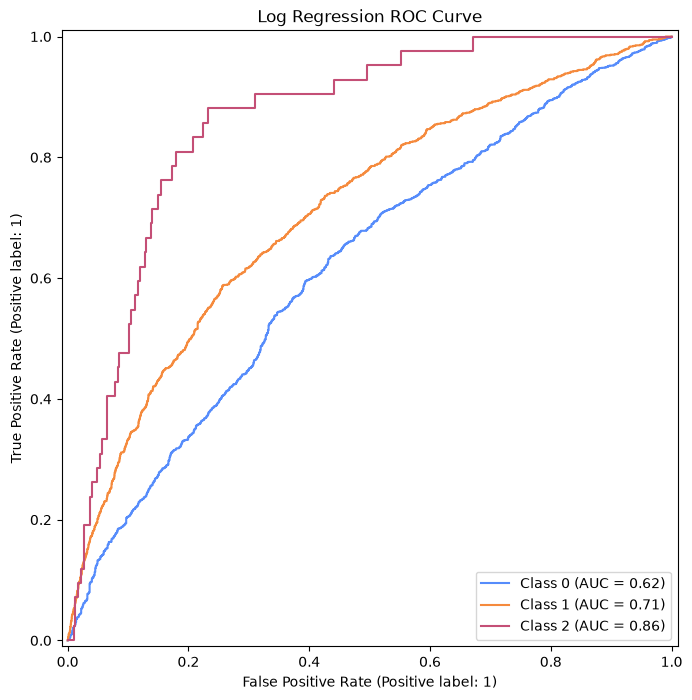

0 [0.81 0.25 0.24 ... 0.34 0.22 0.13]
1 [0.15 0.07 0.1  ... 0.6  0.77 0.82]
2 [0.04 0.67 0.66 ... 0.06 0.01 0.05]


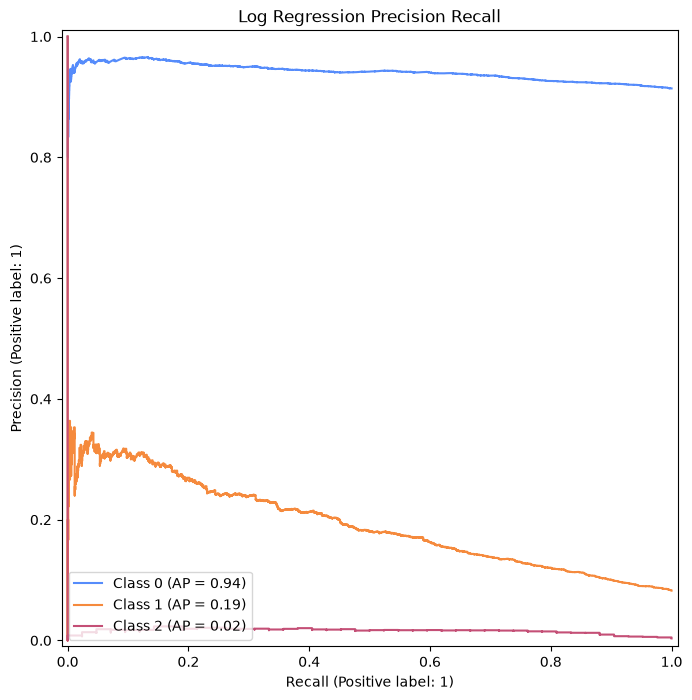

Macro Average Precision Score: 0.383


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6018.24it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

SGD Classifier Test Cross Val Accuracy: 0.4363 (0.0333)
SGD Classifier Test Cross Val Balanced Accuracy: 0.6475 (0.0242)
SGD Classifier Test Cross Val F1 Macro: 0.2777 (0.0155)
SGD Classifier Test Cross Val ROC AUC: 0.7375 (0.0105)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6975.95it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.95      0.56      0.71     11415
           1       0.17      0.58      0.26      1031
           2       0.02      0.79      0.03        42

    accuracy                           0.57     12488
   macro avg       0.38      0.64      0.33     12488
weighted avg       0.88      0.57      0.67     12488

Confusion Matrix
[[6430 2973 2012]
 [ 351  595   85]
 [   5    4   33]]


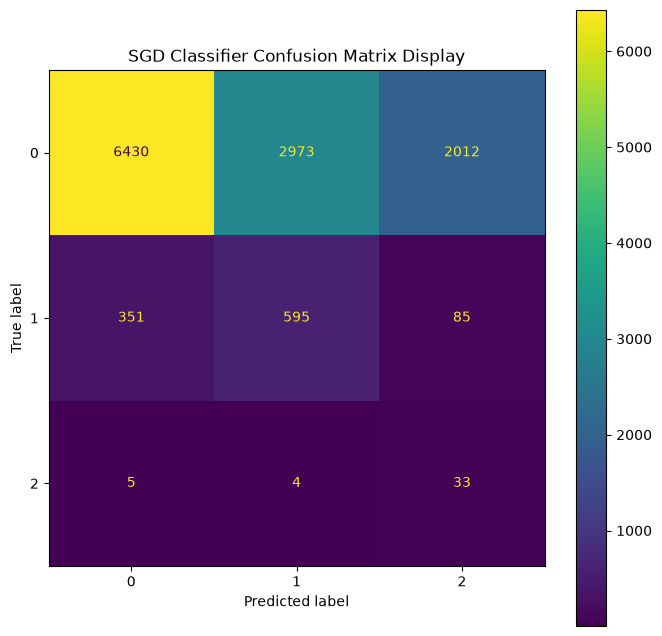

0 [0.79 0.34 0.36 ... 0.43 0.41 0.4 ]
1 [0.21 0.03 0.04 ... 0.57 0.59 0.6 ]
2 [1.70e-04 6.24e-01 5.96e-01 ... 1.47e-03 1.25e-04 4.03e-04]


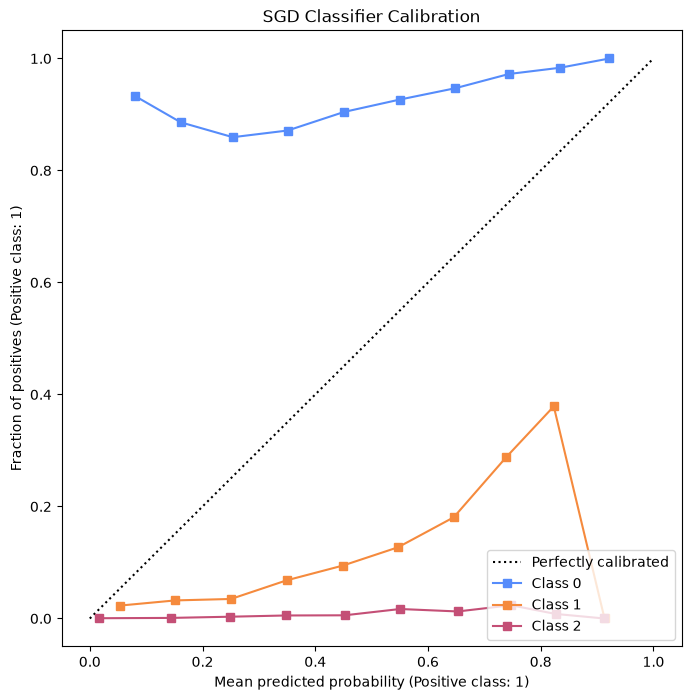

0 [0.79 0.34 0.36 ... 0.43 0.41 0.4 ]
1 [0.21 0.03 0.04 ... 0.57 0.59 0.6 ]
2 [1.70e-04 6.24e-01 5.96e-01 ... 1.47e-03 1.25e-04 4.03e-04]


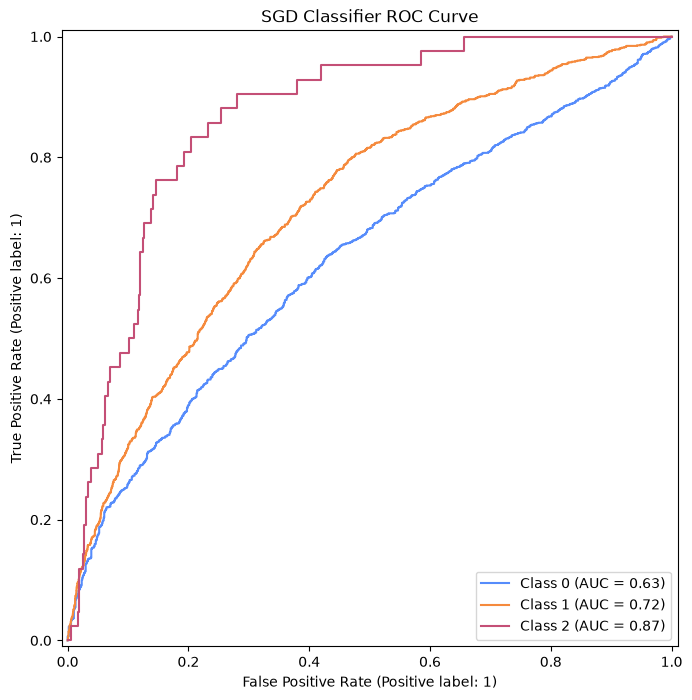

0 [0.79 0.34 0.36 ... 0.43 0.41 0.4 ]
1 [0.21 0.03 0.04 ... 0.57 0.59 0.6 ]
2 [1.70e-04 6.24e-01 5.96e-01 ... 1.47e-03 1.25e-04 4.03e-04]


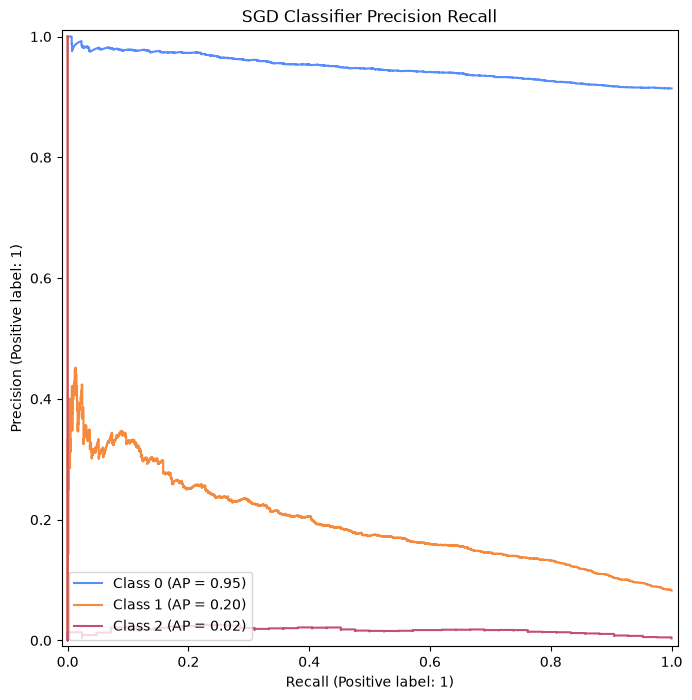

Macro Average Precision Score: 0.387


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


K-Neighbours Classifier Test Cross Val Accuracy: 0.7328 (0.0045)
K-Neighbours Classifier Test Cross Val Balanced Accuracy: 0.6228 (0.0087)
K-Neighbours Classifier Test Cross Val F1 Macro: 0.4165 (0.0019)
K-Neighbours Classifier Test Cross Val ROC AUC: 0.7610 (0.0038)
Classification Report
              precision    recall  f1-score   support

           0       0.97      0.76      0.85     11415
           1       0.23      0.73      0.35      1031
           2       0.06      0.43      0.10        42

    accuracy                           0.75     12488
   macro avg       0.42      0.64      0.43     12488
weighted avg       0.90      0.75      0.81     12488

Confusion Matrix
[[8647 2490  278]
 [ 275  749    7]
 [  18    6   18]]


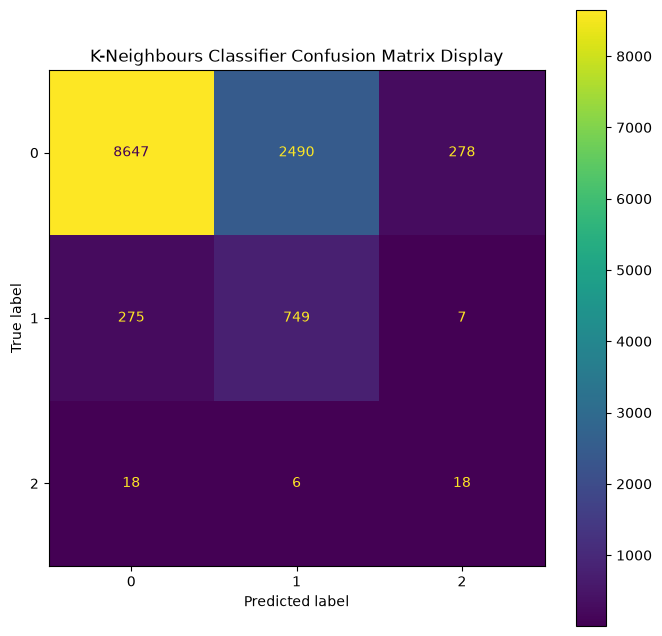

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


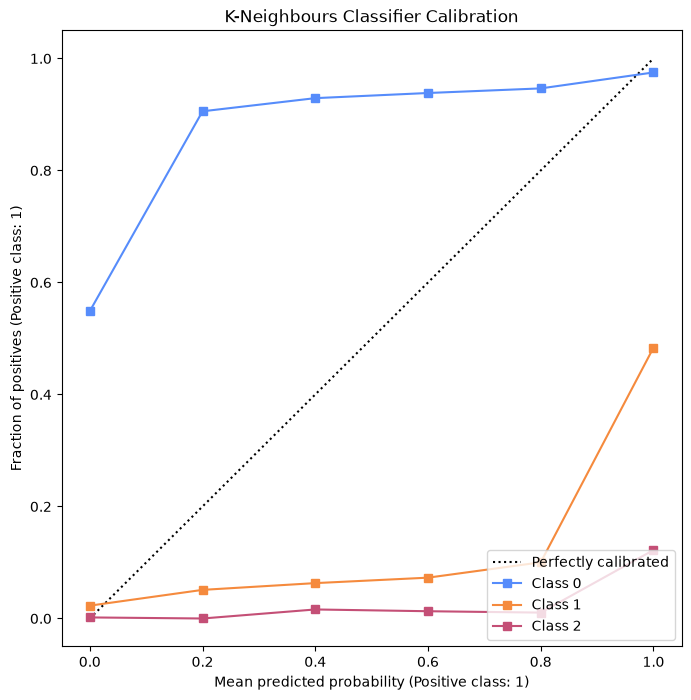

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


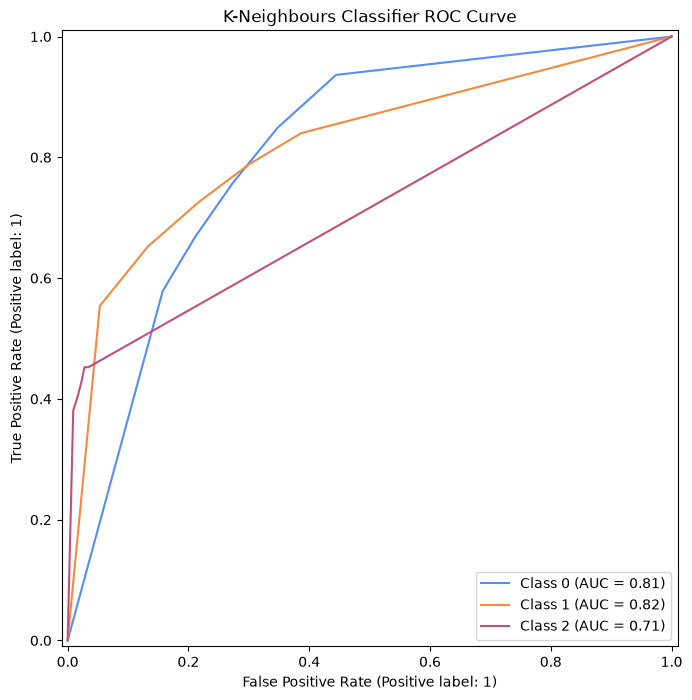

0 [1.  1.  0.6 ... 0.2 1.  1. ]
1 [0.  0.  0.4 ... 0.8 0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


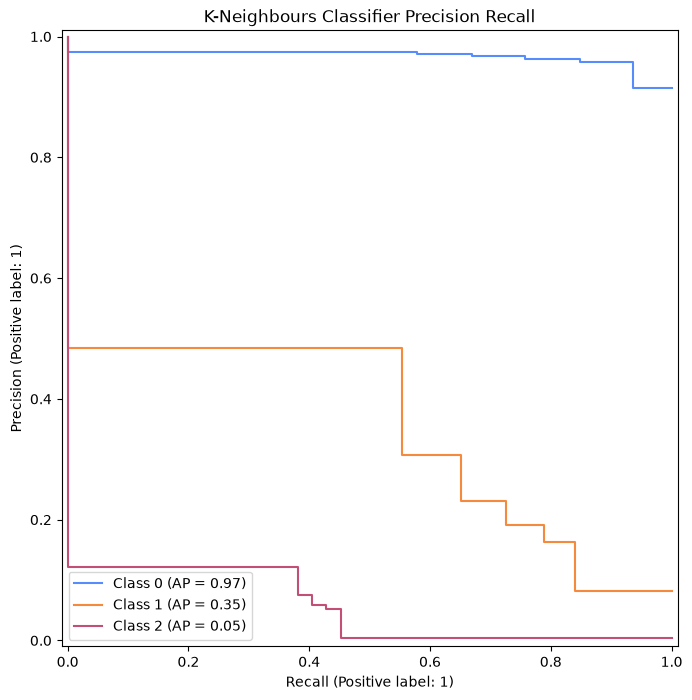

Macro Average Precision Score: 0.456


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Decision Tree Classifier Test Cross Val Accuracy: 0.5807 (0.1177)
Decision Tree Classifier Test Cross Val Balanced Accuracy: 0.5343 (0.0088)
Decision Tree Classifier Test Cross Val F1 Macro: 0.3310 (0.0444)
Decision Tree Classifier Test Cross Val ROC AUC: 0.6909 (0.0168)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.73      0.83     11415
           1       0.19      0.60      0.29      1031
           2       0.04      0.48      0.07        42

    accuracy                           0.72     12488
   macro avg       0.40      0.60      0.40     12488
weighted avg       0.89      0.72      0.78     12488

Confusion Matrix
[[8389 2536  490]
 [ 397  614   20]
 [  16    6   20]]


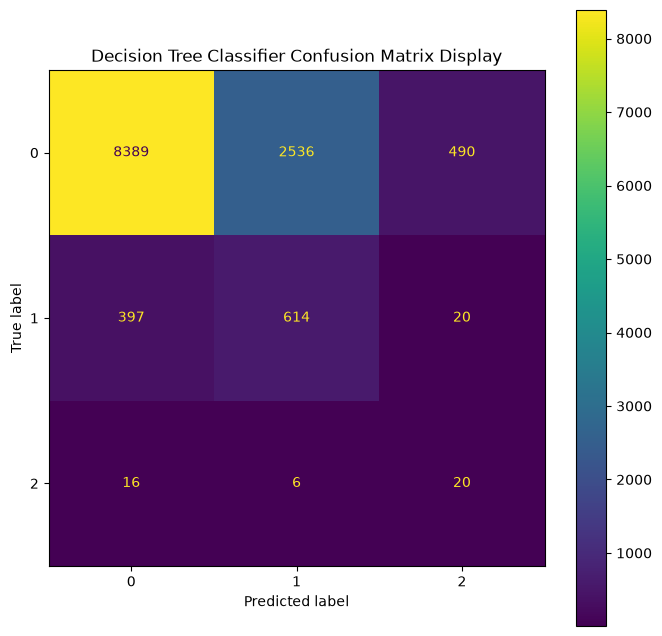

0 [1.   0.99 0.99 ... 0.57 0.12 0.59]
1 [0.   0.01 0.01 ... 0.43 0.88 0.41]
2 [0. 0. 0. ... 0. 0. 0.]


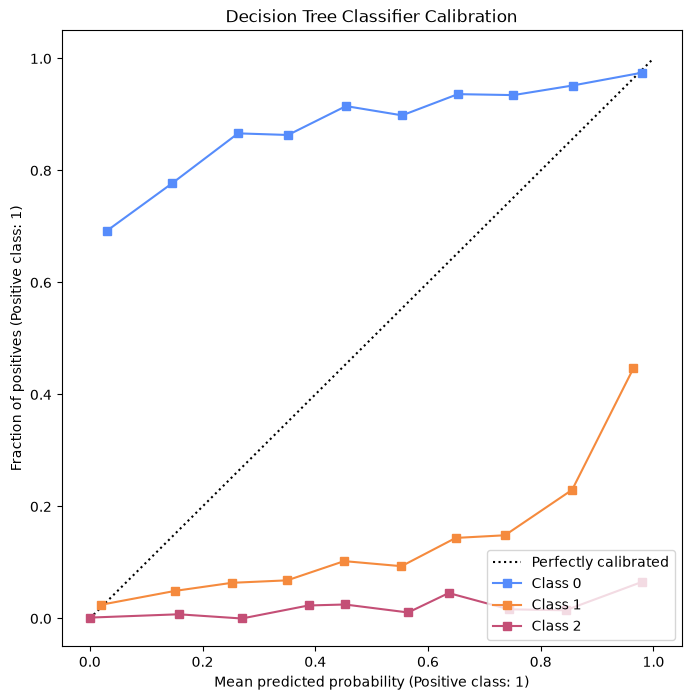

0 [1.   0.99 0.99 ... 0.57 0.12 0.59]
1 [0.   0.01 0.01 ... 0.43 0.88 0.41]
2 [0. 0. 0. ... 0. 0. 0.]


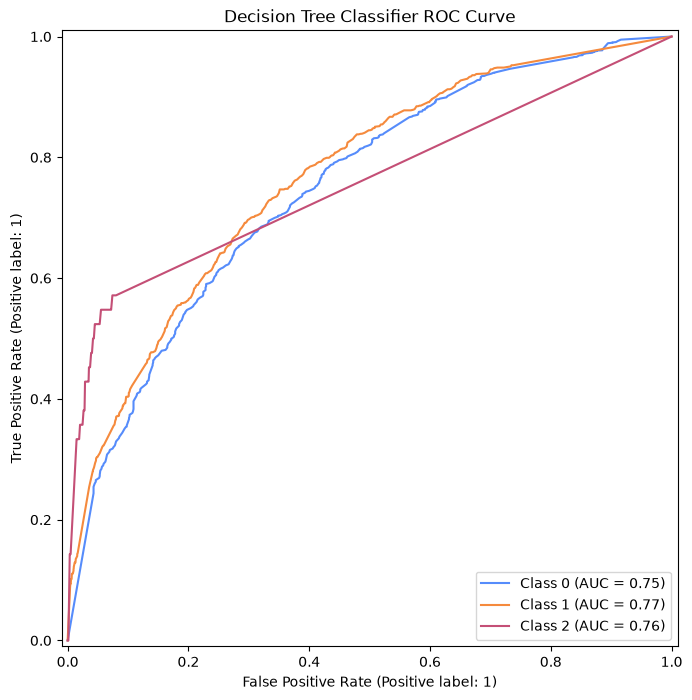

0 [1.   0.99 0.99 ... 0.57 0.12 0.59]
1 [0.   0.01 0.01 ... 0.43 0.88 0.41]
2 [0. 0. 0. ... 0. 0. 0.]


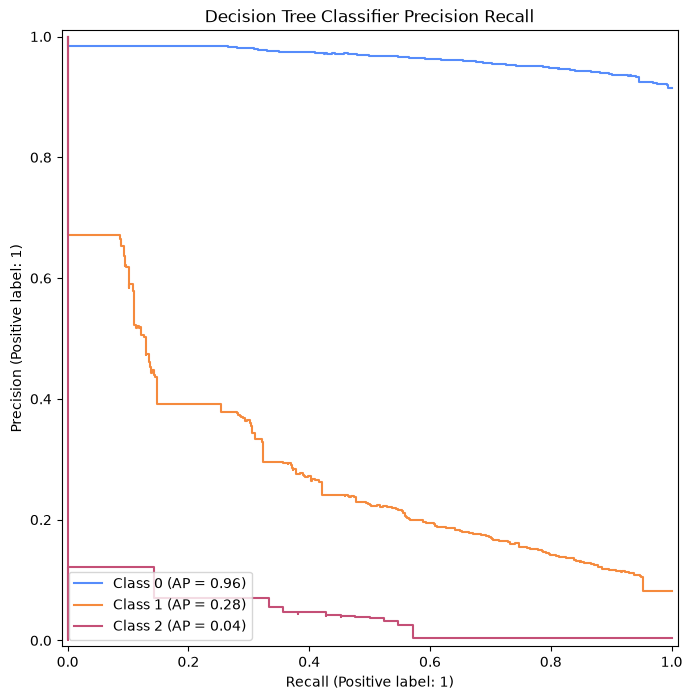

Macro Average Precision Score: 0.430


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Linear SVC Test Cross Val Accuracy: 0.1324 (0.0683)
Linear SVC Test Cross Val Balanced Accuracy: 0.5613 (0.0129)
Linear SVC Test Cross Val F1 Macro: 0.1061 (0.0481)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.96      0.08      0.15     11415
           1       0.11      0.81      0.19      1031
           2       0.01      0.90      0.02        42

    accuracy                           0.14     12488
   macro avg       0.36      0.60      0.12     12488
weighted avg       0.88      0.14      0.15     12488

Confusion Matrix
[[ 916 6862 3637]
 [  43  838  150]
 [   0    4   38]]


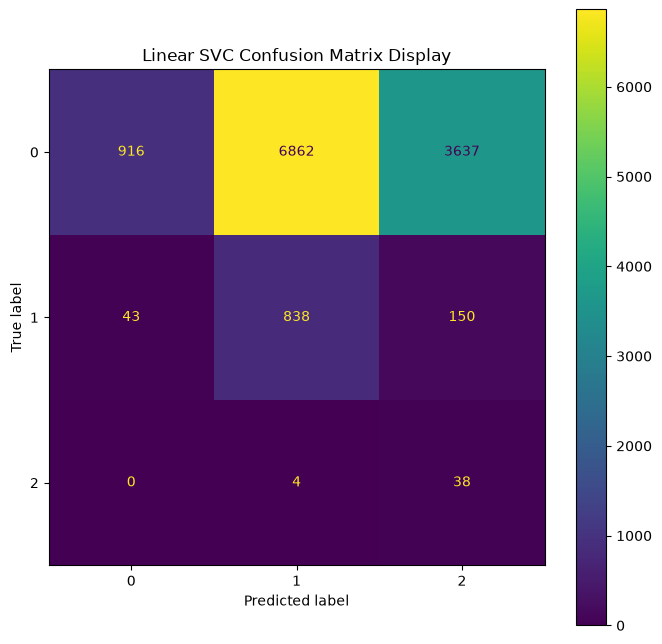

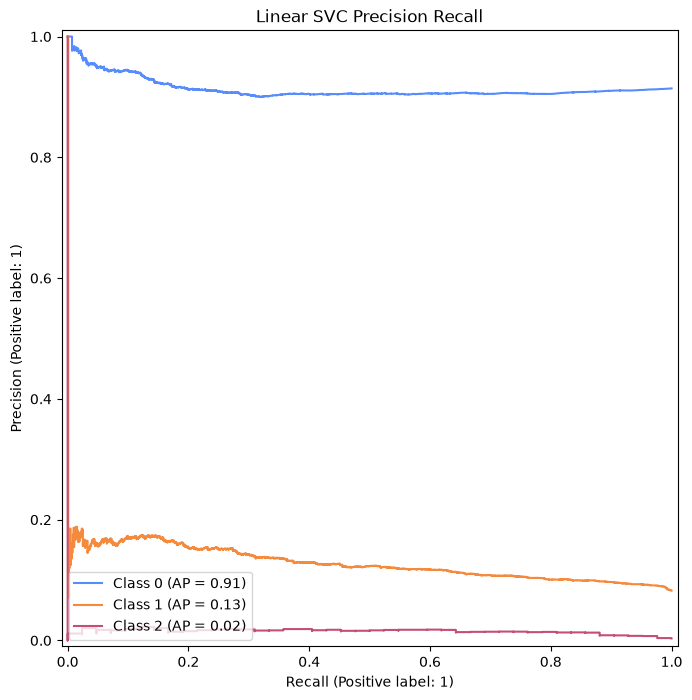

Macro Average Precision Score: 0.352


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Linear Discriminant Analysis Test Cross Val Accuracy: 0.5067 (0.0019)
Linear Discriminant Analysis Test Cross Val Balanced Accuracy: 0.6367 (0.0122)
Linear Discriminant Analysis Test Cross Val F1 Macro: 0.3084 (0.0012)
Linear Discriminant Analysis Test Cross Val ROC AUC: 0.7357 (0.0081)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.48      0.64     11415
           1       0.16      0.65      0.26      1031
           2       0.01      0.81      0.03        42

    accuracy                           0.50     12488
   macro avg       0.37      0.65      0.31     12488
weighted avg       0.88      0.50      0.61     12488

Confusion Matrix
[[5515 3520 2380]
 [ 275  667   89]
 [   6    2   34]]


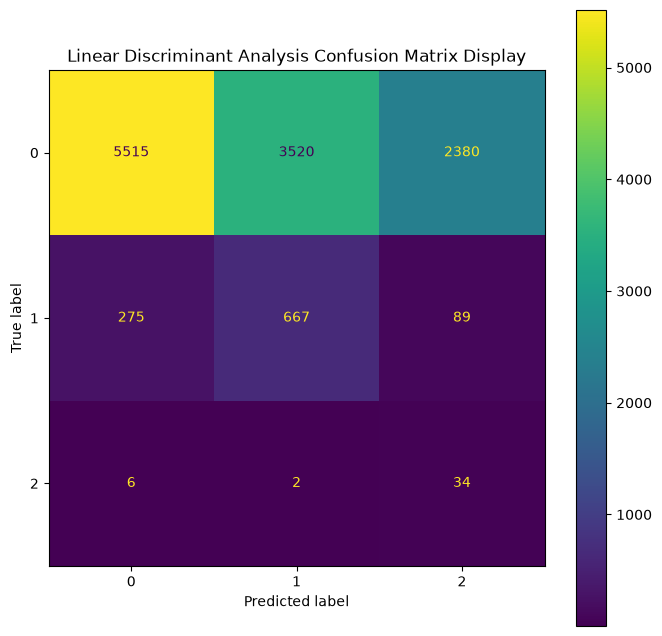

0 [0.88 0.1  0.15 ... 0.3  0.16 0.21]
1 [0.12 0.01 0.02 ... 0.7  0.84 0.79]
2 [2.20e-03 8.89e-01 8.31e-01 ... 2.00e-03 1.01e-04 2.39e-03]


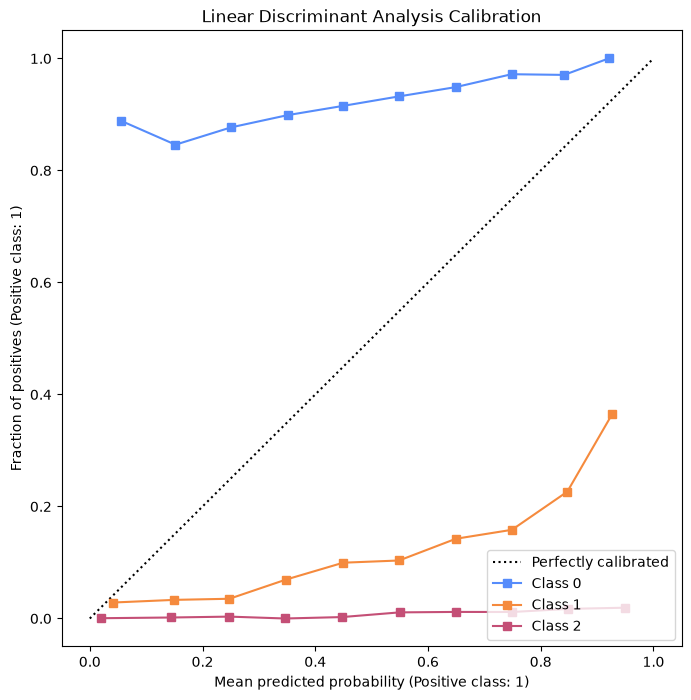

0 [0.88 0.1  0.15 ... 0.3  0.16 0.21]
1 [0.12 0.01 0.02 ... 0.7  0.84 0.79]
2 [2.20e-03 8.89e-01 8.31e-01 ... 2.00e-03 1.01e-04 2.39e-03]


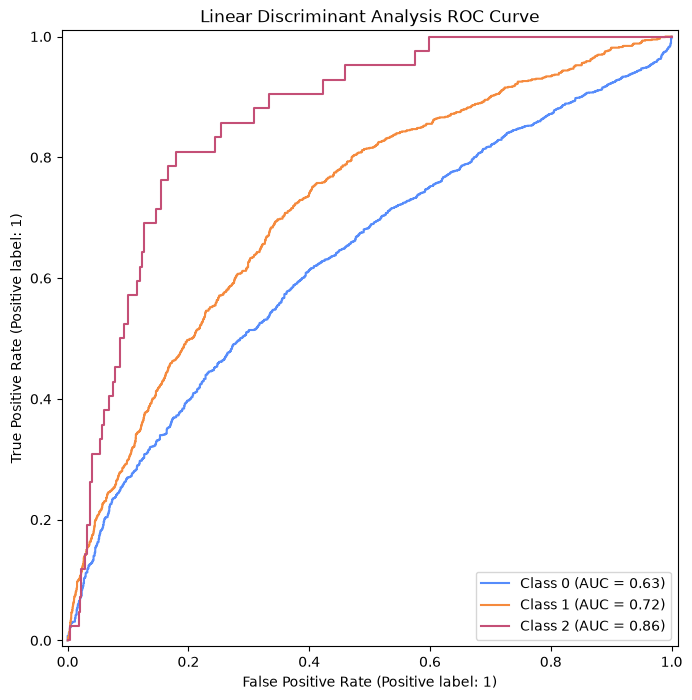

0 [0.88 0.1  0.15 ... 0.3  0.16 0.21]
1 [0.12 0.01 0.02 ... 0.7  0.84 0.79]
2 [2.20e-03 8.89e-01 8.31e-01 ... 2.00e-03 1.01e-04 2.39e-03]


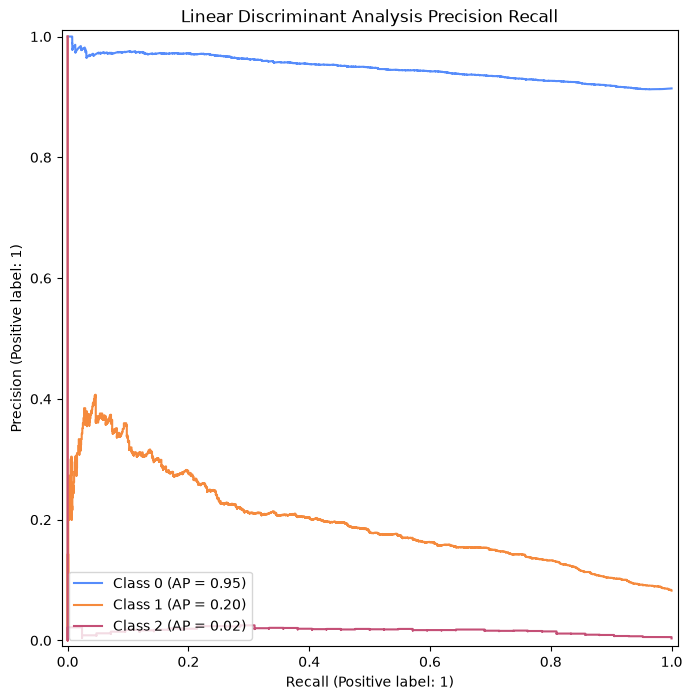

Macro Average Precision Score: 0.387


[Pipeline(memory=Memory(location=./model-cache/joblib),
          steps=[('continuous_data_transforms',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('box_cox',
                                                   PowerTransformer(method='box-cox',
                                                                    standardize=False),
                                                   ('Floor Area (m^2)',))],
                                    verbose_feature_names_out=False)),
                 ('drop_columns_transform',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[(...
                                                                    VarianceThreshold()),
                                                                   ('recursive_feature_selection',
                                                                    RFE(estimator=LogisticRegression(cl

In [4]:
primary_build_model_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                        X_ORDINAL_ENCODED_CATEGORIES,
                                                        HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                        LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipelines = run_model_pipeline(primary_build_model_pipeline, physical_x_train, physical_y_train,
                                        physical_x_test,
                                        physical_y_test)

physical_pipelines

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6393.28it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

K-Neighbours Bagging Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                   verbose_feature_names_out=False)),
                ('target_resampling

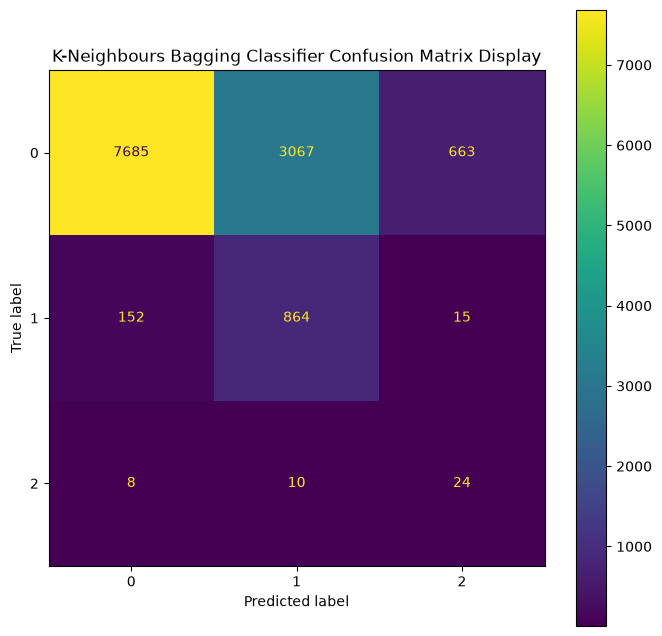

0 [0.99 0.76 0.65 ... 0.16 0.68 0.53]
1 [0.01 0.   0.2  ... 0.84 0.32 0.47]
2 [0.   0.24 0.15 ... 0.   0.   0.  ]


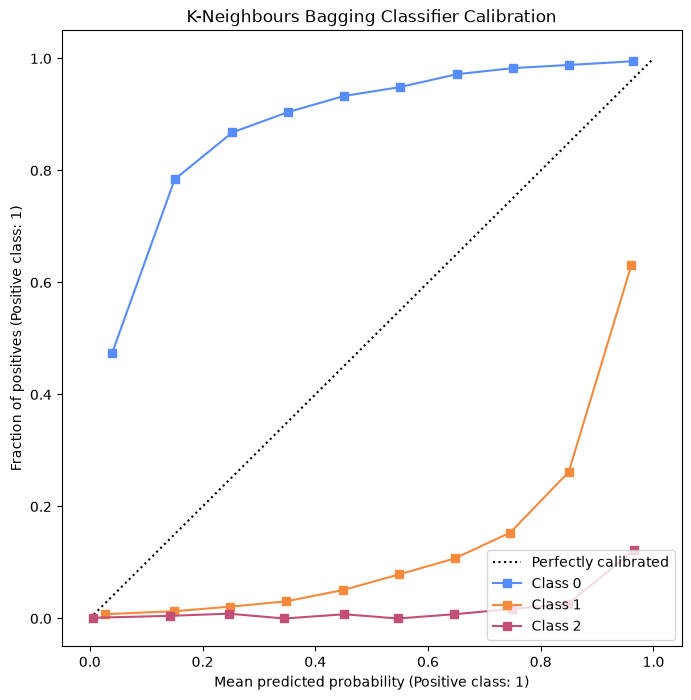

0 [0.99 0.76 0.65 ... 0.16 0.68 0.53]
1 [0.01 0.   0.2  ... 0.84 0.32 0.47]
2 [0.   0.24 0.15 ... 0.   0.   0.  ]


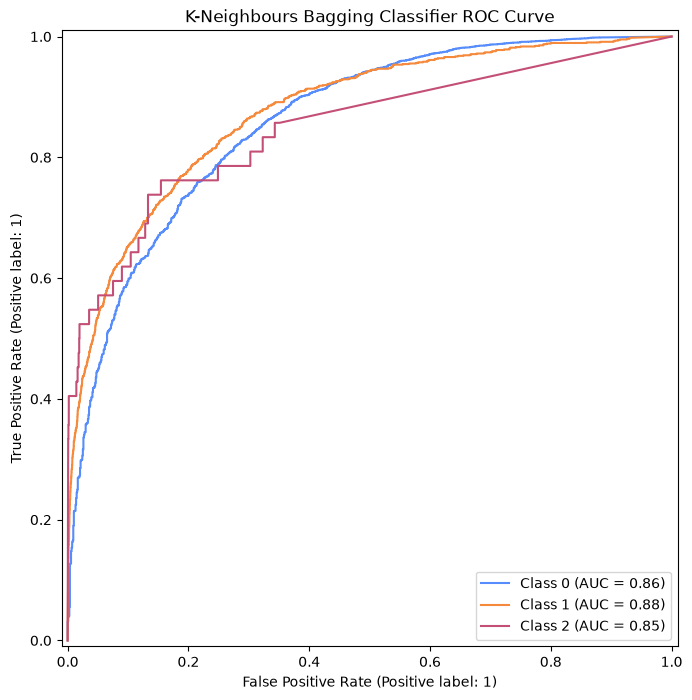

0 [0.99 0.76 0.65 ... 0.16 0.68 0.53]
1 [0.01 0.   0.2  ... 0.84 0.32 0.47]
2 [0.   0.24 0.15 ... 0.   0.   0.  ]


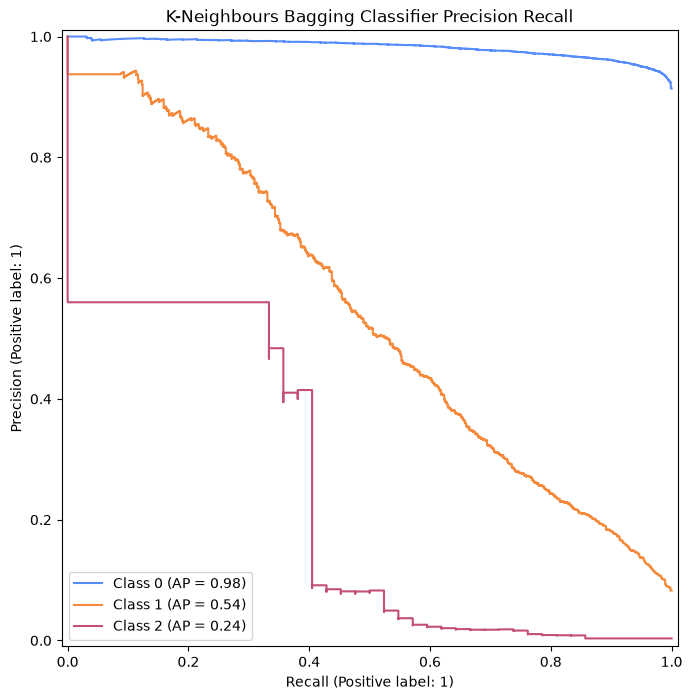

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [5]:
gc.collect()
torch.cuda.empty_cache()

# run_kneighbours_bagging_classifier_pipeline(build_model_pipeline, primary_x_train, primary_y_train, primary_x_test, primary_y_test)

physical_kneighbours_bagging_classifier_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                                            X_ORDINAL_ENCODED_CATEGORIES,
                                                                            HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                                            LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_kneighbours_bagging_classifier_pipeline(physical_kneighbours_bagging_classifier_pipeline,
                                                                physical_x_train,
                                                                physical_y_train,
                                                                physical_x_test,
                                                                physical_y_test)

physical_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7121.41it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Random Forest Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                                  slice(None, None, None))],
                                   

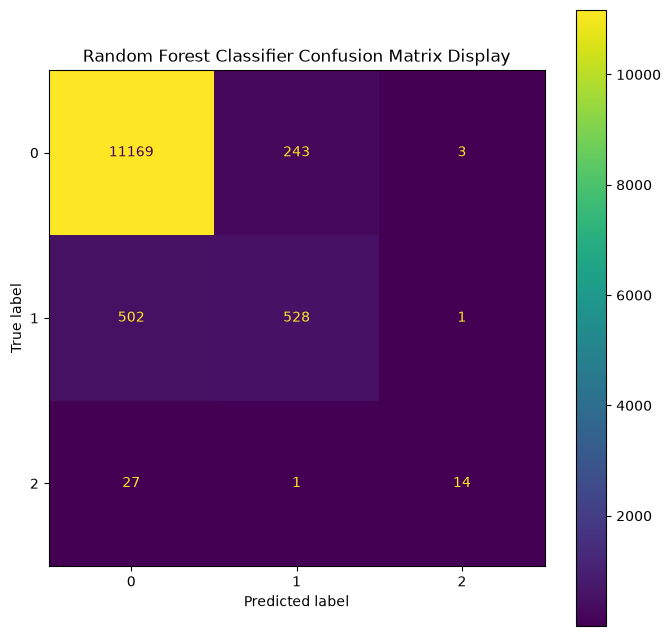

0 [0.99 0.92 0.83 ... 0.66 0.84 0.83]
1 [0.01 0.05 0.11 ... 0.34 0.16 0.17]
2 [0.   0.03 0.06 ... 0.   0.   0.  ]


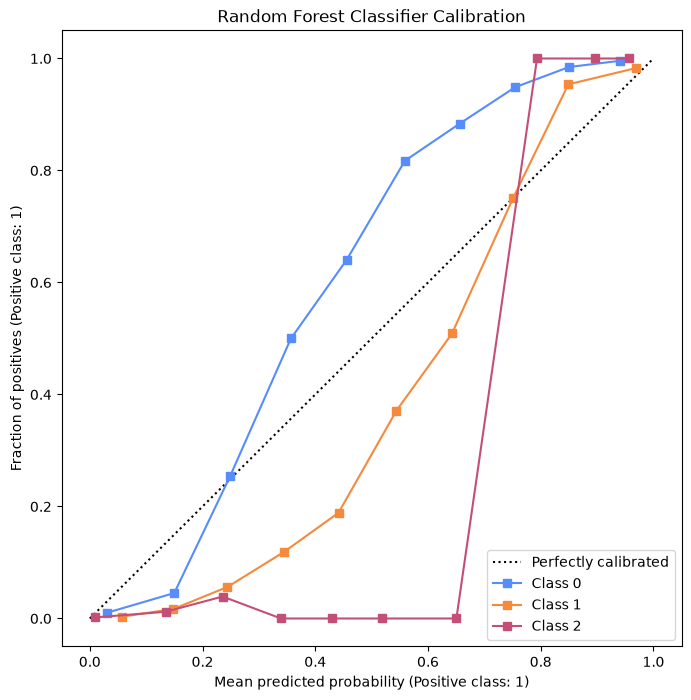

0 [0.99 0.92 0.83 ... 0.66 0.84 0.83]
1 [0.01 0.05 0.11 ... 0.34 0.16 0.17]
2 [0.   0.03 0.06 ... 0.   0.   0.  ]


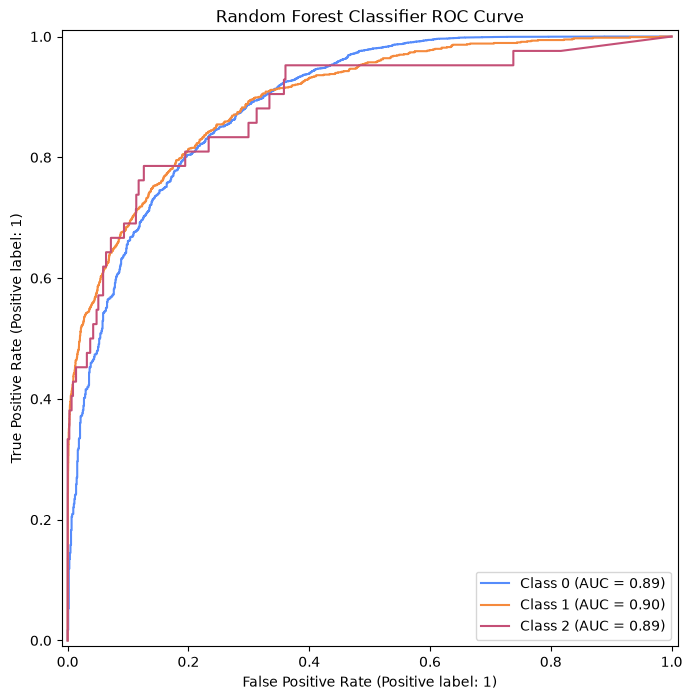

0 [0.99 0.92 0.83 ... 0.66 0.84 0.83]
1 [0.01 0.05 0.11 ... 0.34 0.16 0.17]
2 [0.   0.03 0.06 ... 0.   0.   0.  ]


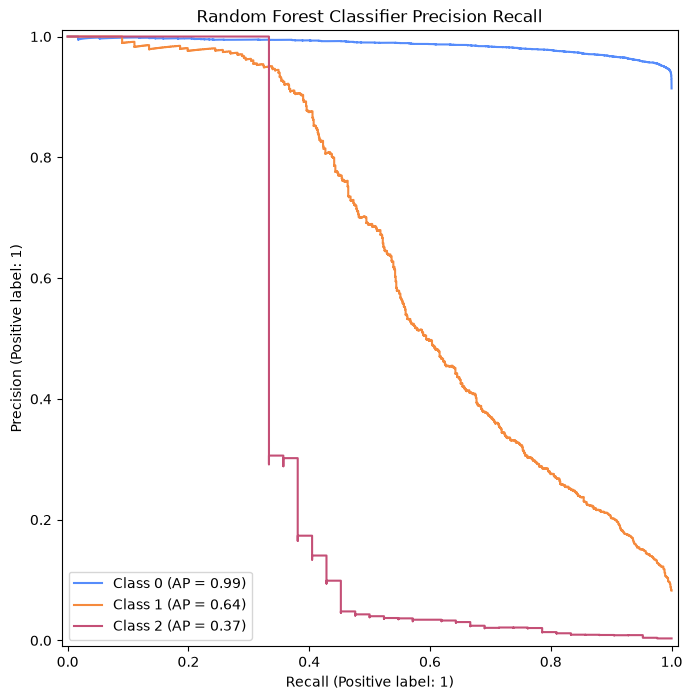

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [6]:
gc.collect()
torch.cuda.empty_cache()

# run_kneighbours_bagging_classifier_pipeline(build_model_pipeline, primary_x_train, primary_y_train, primary_x_test, primary_y_test)

random_forest_classifier_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                             X_ORDINAL_ENCODED_CATEGORIES,
                                                             HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                             LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_random_forest_pipeline(random_forest_classifier_pipeline, physical_x_train,
                                               physical_y_train,
                                               physical_x_test,
                                               physical_y_test)

physical_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6682.13it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

ADA Boost Decision Tree Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  ('Floor Area (m^2)',))],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'E...
                                                                                                    ma

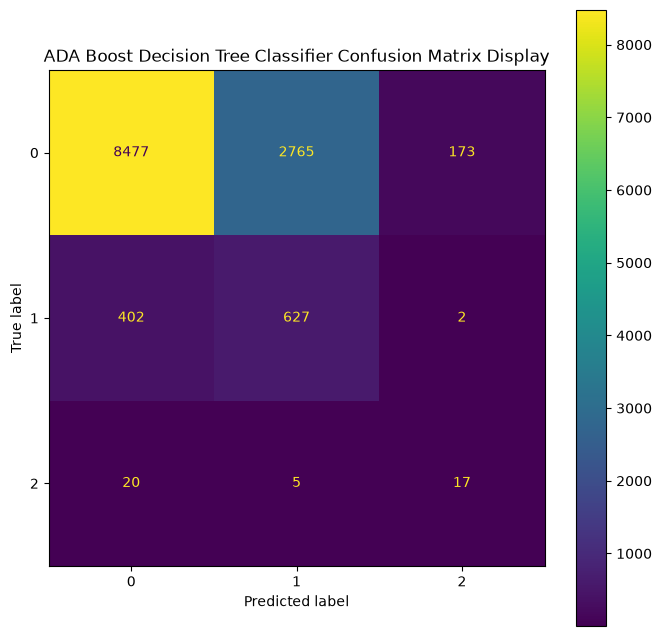

0 [0.39 0.36 0.35 ... 0.37 0.36 0.37]
1 [0.35 0.31 0.32 ... 0.38 0.38 0.37]
2 [0.26 0.34 0.33 ... 0.26 0.26 0.26]


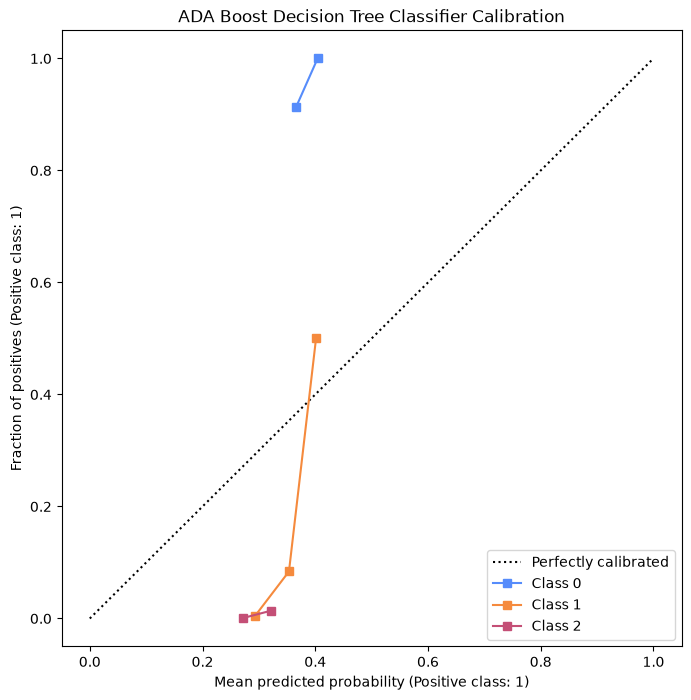

0 [0.39 0.36 0.35 ... 0.37 0.36 0.37]
1 [0.35 0.31 0.32 ... 0.38 0.38 0.37]
2 [0.26 0.34 0.33 ... 0.26 0.26 0.26]


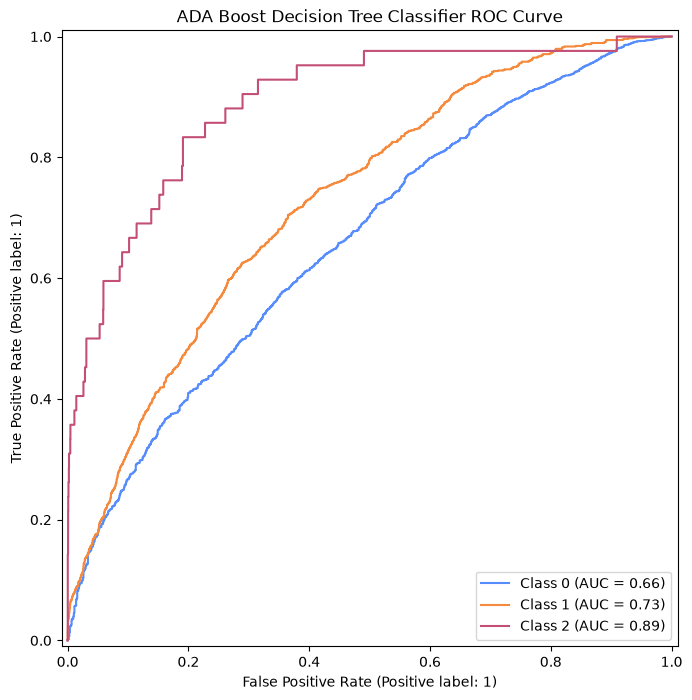

0 [0.39 0.36 0.35 ... 0.37 0.36 0.37]
1 [0.35 0.31 0.32 ... 0.38 0.38 0.37]
2 [0.26 0.34 0.33 ... 0.26 0.26 0.26]


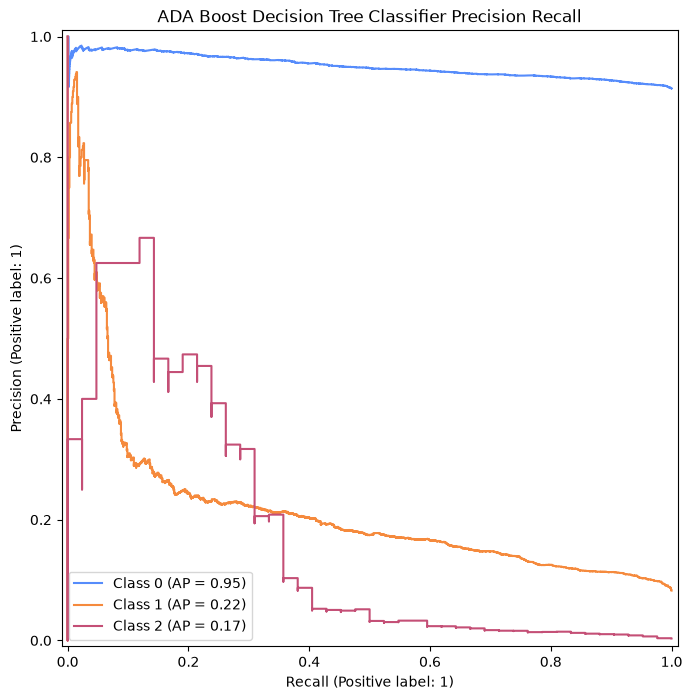

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [7]:
gc.collect()
torch.cuda.empty_cache()

physical_adaboost_decision_tree_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                                    X_ORDINAL_ENCODED_CATEGORIES,
                                                                    HIGH_CARDINALITY_ENCODED_CATEGORIES,
                                                                    LOW_CARDINALITY_ENCODED_CATEGORIES)

physical_pipeline = run_adaboost_decision_tree_pipeline(physical_adaboost_decision_tree_pipeline,
                                                        physical_x_train,
                                                        physical_y_train,
                                                        physical_x_test,
                                                        physical_y_test)

physical_pipeline

In [21]:
print(primary_y_train[INFERRED_TARGET_FIELD].value_counts())
print(physical_y_train[INFERRED_TARGET_FIELD].value_counts())

k_neighbours_estimator: RandomizedSearchCV = joblib.load(BAGGING_CLASSIFIER_KNEIGHBOURS_DUMP)

Inferred Planning Decision
0    61734
1     5370
2      237
Name: count, dtype: int64
Inferred Planning Decision
0    23024
1     2103
2       77
Name: count, dtype: int64


Inferred Planning Decision
0    23024
1     2103
2       77
Name: count, dtype: int64


PermutationExplainer explainer: 51it [1:28:43, 106.46s/it]                        

SHAP explanation for class: Approve


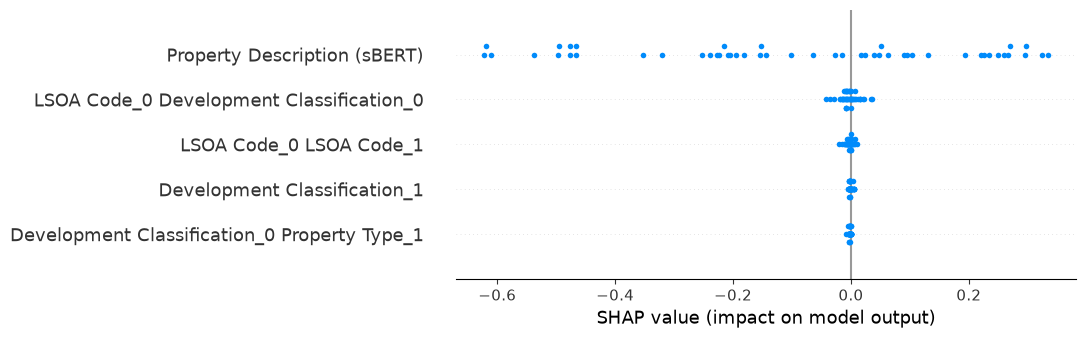

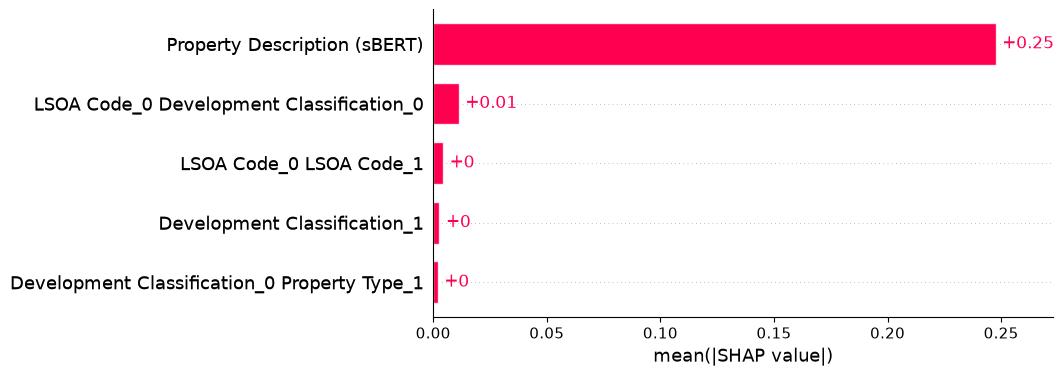

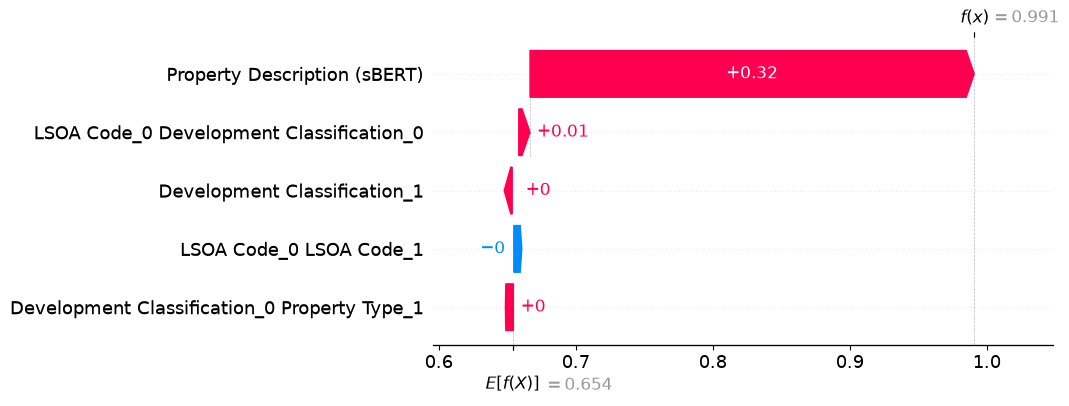

SHAP explanation for class: Refuse


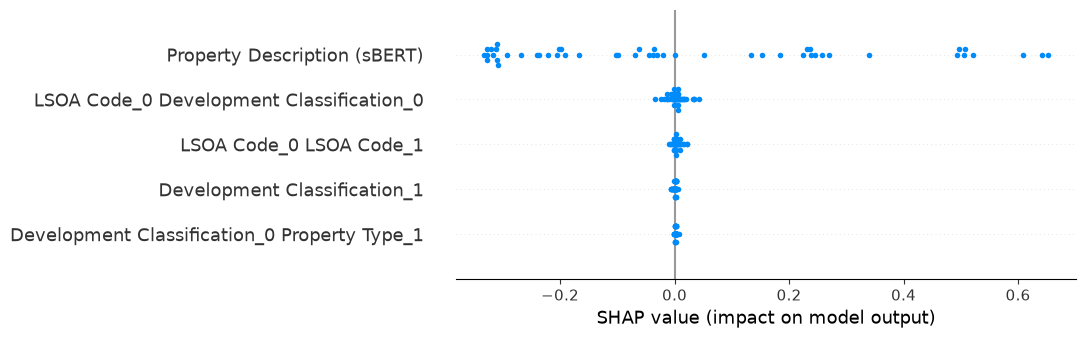

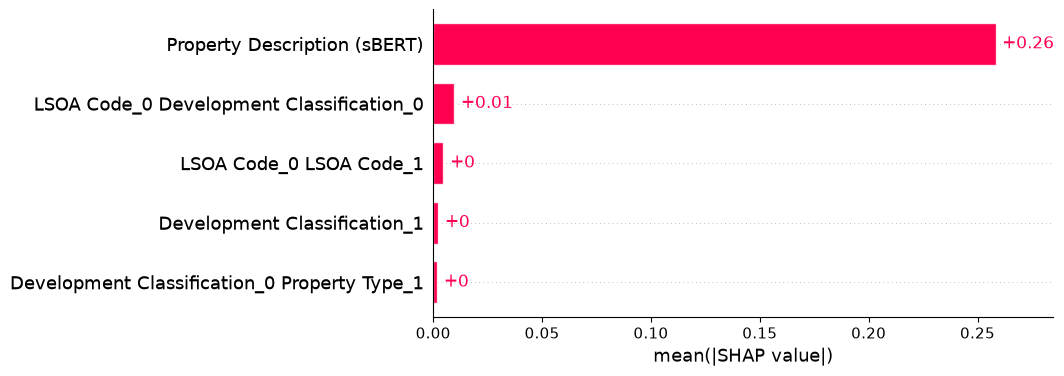

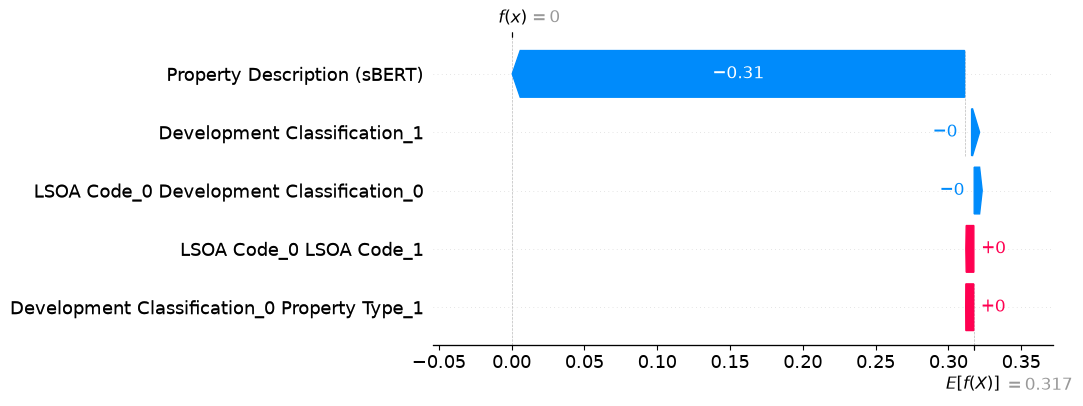

SHAP explanation for class: Split


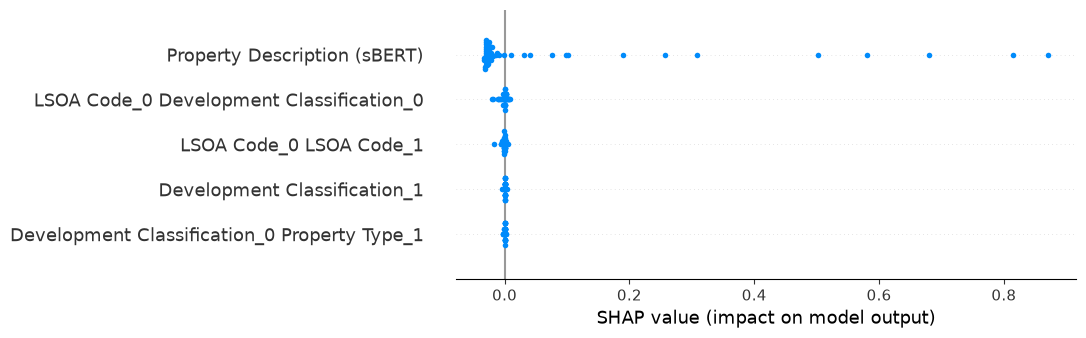

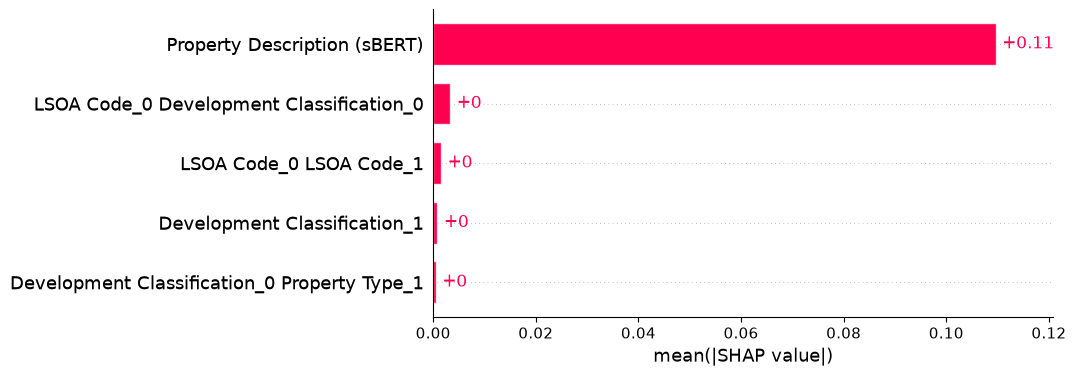

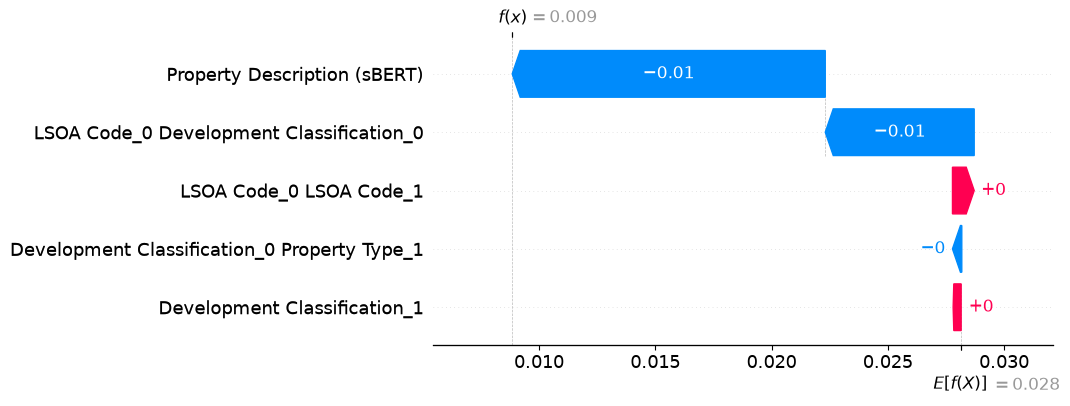

In [36]:
run_shap_analysis(k_neighbours_estimator.best_estimator_, physical_x_train, physical_x_test)

                 total  errors  error_rate  error_rate_pct
confidence_band                                           
(0.499, 0.6]      2406    1122    0.466334       46.633416
(0.6, 0.7]        2463     979    0.397483       39.748274
(0.7, 0.8]        2157     729    0.337969       33.796940
(0.8, 0.9]        2194     571    0.260255       26.025524
(0.9, 1.0]        3018     381    0.126243       12.624254


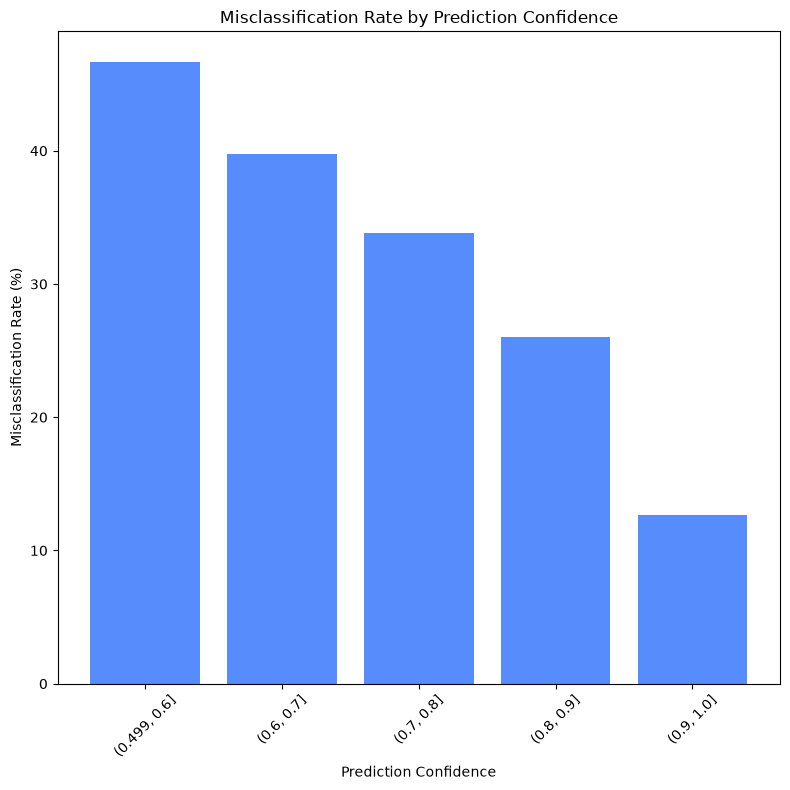

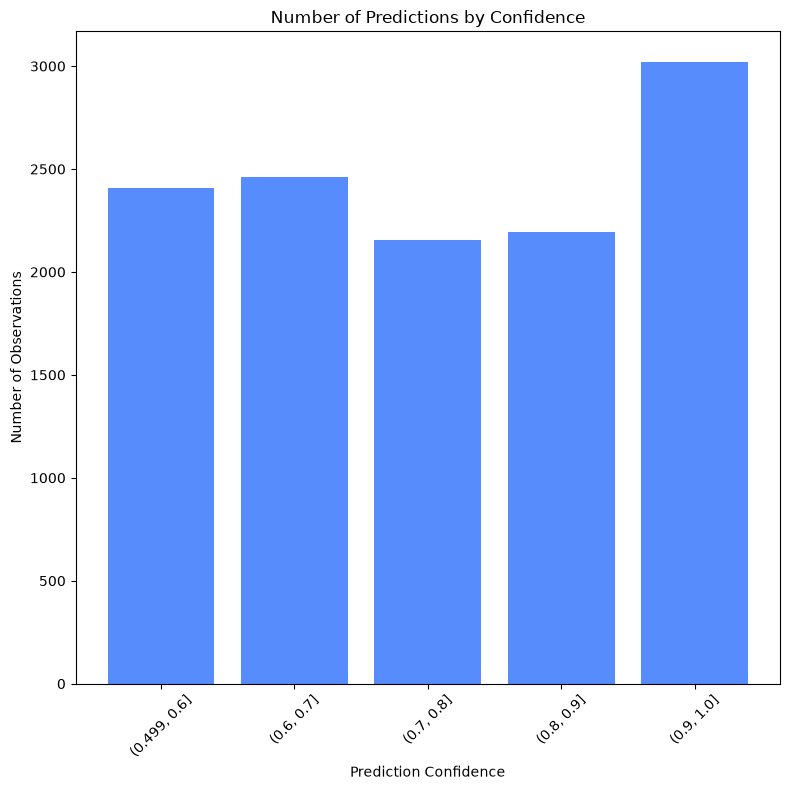

In [11]:
run_shap_inconsistency_analysis(k_neighbours_estimator.best_estimator_, physical_x_test, physical_y_test)

In [17]:
def _get_primary_build_model_pipeline() -> Pipeline:
    return get_build_model_pipeline([], DROPPED_CATEGORIES,
                                    X_ORDINAL_ENCODED_CATEGORIES,
                                    [c for c in HIGH_CARDINALITY_ENCODED_CATEGORIES if
                                     c != "Property Type"],
                                    LOW_CARDINALITY_ENCODED_CATEGORIES)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5891.28it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Log Regression Test Cross Val Accuracy: 0.4269 (0.0122)
Log Regression Test Cross Val Balanced Accuracy: 0.6426 (0.0140)
Log Regression Test Cross Val F1 Macro: 0.2795 (0.0070)
Log Regression Test Cross Val ROC AUC: 0.7486 (0.0138)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6570.74it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.43      0.59     30407
           1       0.16      0.65      0.25      2645
           2       0.01      0.82      0.02       116

    accuracy                           0.44     33168
   macro avg       0.37      0.63      0.29     33168
weighted avg       0.89      0.44      0.56     33168

Confusion Matrix
[[12936  9272  8199]
 [  571  1719   355]
 [   13     8    95]]


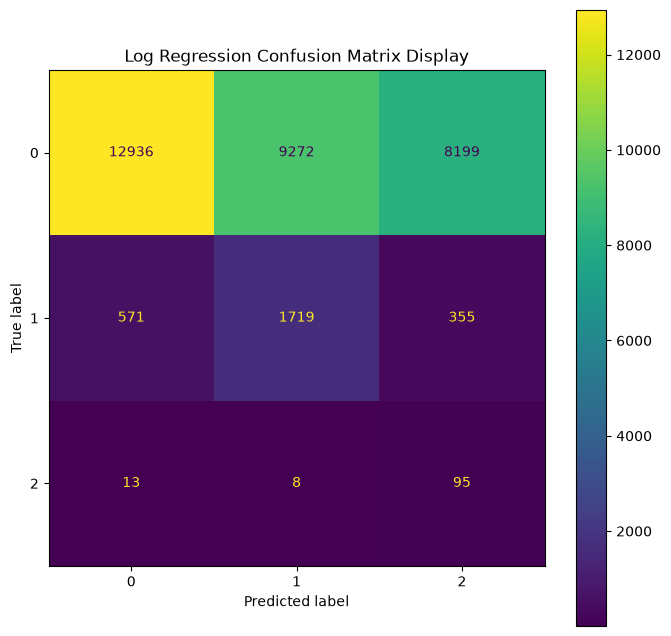

0 [0.58 0.44 0.47 ... 0.2  0.18 0.21]
1 [0.34 0.14 0.32 ... 0.77 0.77 0.64]
2 [0.09 0.42 0.21 ... 0.03 0.06 0.15]


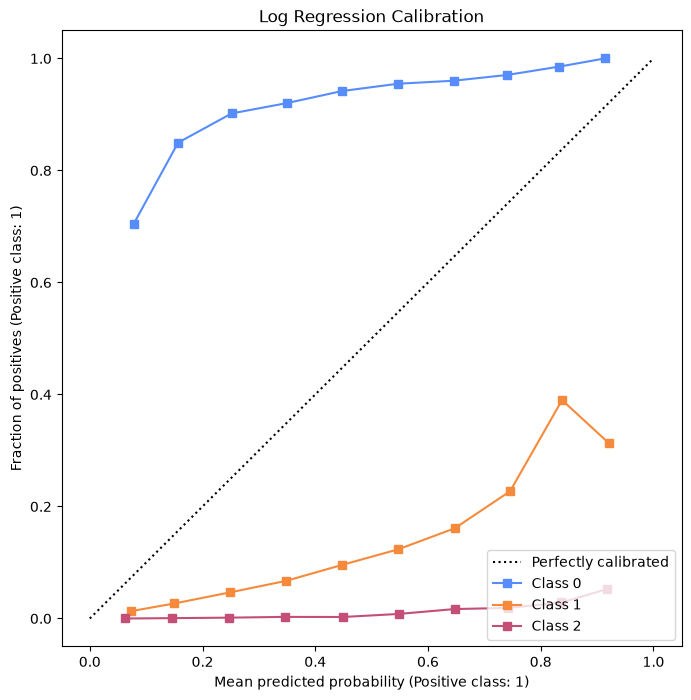

0 [0.58 0.44 0.47 ... 0.2  0.18 0.21]
1 [0.34 0.14 0.32 ... 0.77 0.77 0.64]
2 [0.09 0.42 0.21 ... 0.03 0.06 0.15]


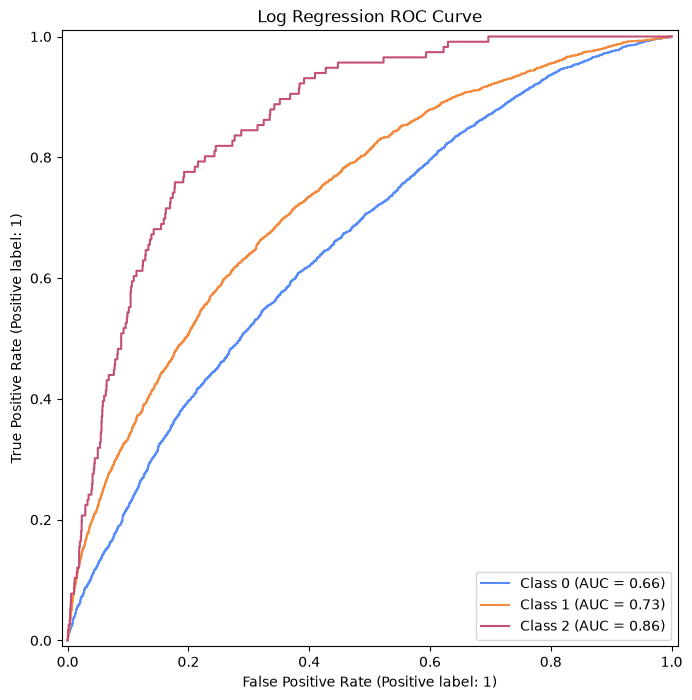

0 [0.58 0.44 0.47 ... 0.2  0.18 0.21]
1 [0.34 0.14 0.32 ... 0.77 0.77 0.64]
2 [0.09 0.42 0.21 ... 0.03 0.06 0.15]


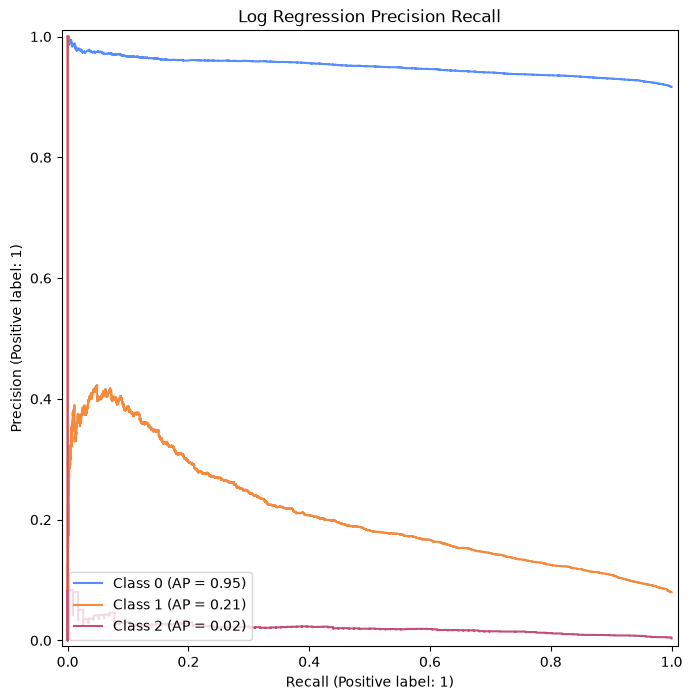

Macro Average Precision Score: 0.393


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categor

SGD Classifier Test Cross Val Accuracy: 0.5170 (0.0357)
SGD Classifier Test Cross Val Balanced Accuracy: 0.6382 (0.0273)
SGD Classifier Test Cross Val F1 Macro: 0.3127 (0.0162)
SGD Classifier Test Cross Val ROC AUC: 0.7475 (0.0161)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.96      0.39      0.55     30407
           1       0.15      0.69      0.25      2645
           2       0.01      0.81      0.02       116

    accuracy                           0.41     33168
   macro avg       0.37      0.63      0.27     33168
weighted avg       0.89      0.41      0.53     33168

Confusion Matrix
[[11770 10317  8320]
 [  488  1817   340]
 [   15     7    94]]


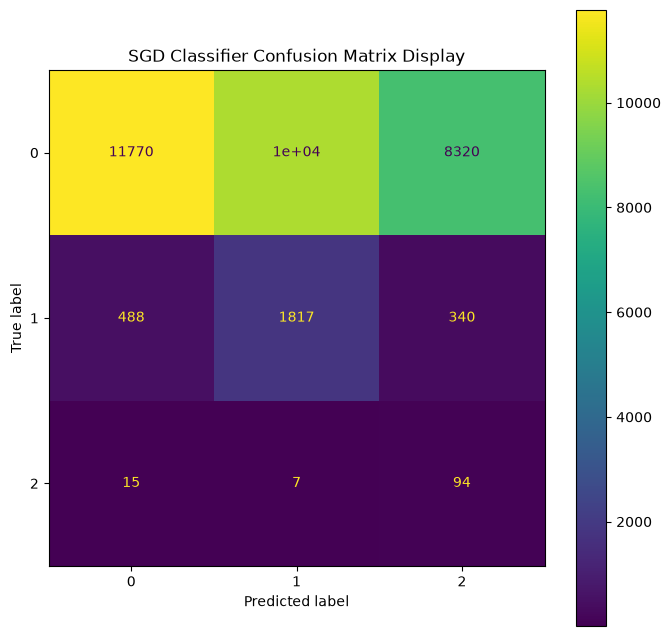

0 [0.56 0.42 0.47 ... 0.28 0.25 0.25]
1 [0.43 0.1  0.31 ... 0.72 0.75 0.7 ]
2 [0.01 0.49 0.22 ... 0.   0.   0.05]


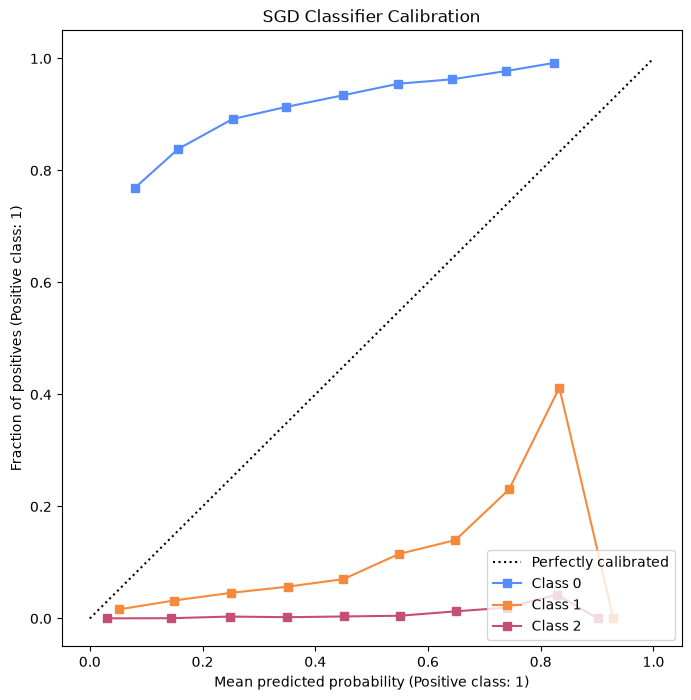

0 [0.56 0.42 0.47 ... 0.28 0.25 0.25]
1 [0.43 0.1  0.31 ... 0.72 0.75 0.7 ]
2 [0.01 0.49 0.22 ... 0.   0.   0.05]


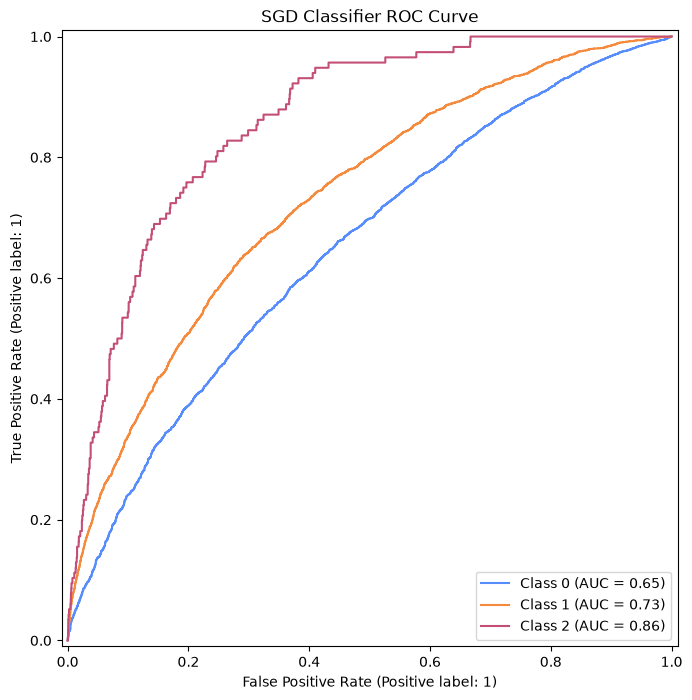

0 [0.56 0.42 0.47 ... 0.28 0.25 0.25]
1 [0.43 0.1  0.31 ... 0.72 0.75 0.7 ]
2 [0.01 0.49 0.22 ... 0.   0.   0.05]


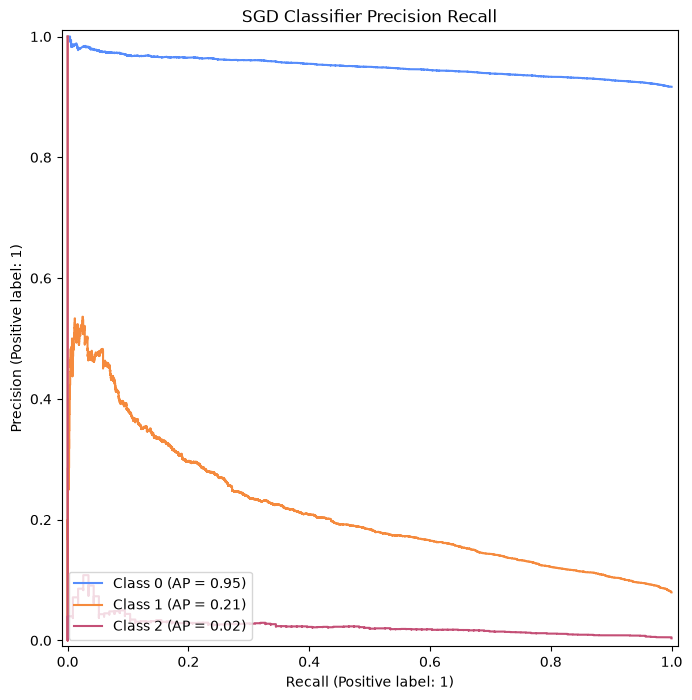

Macro Average Precision Score: 0.396


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during trans

K-Neighbours Classifier Test Cross Val Accuracy: 0.7178 (0.0046)
K-Neighbours Classifier Test Cross Val Balanced Accuracy: 0.5928 (0.0081)
K-Neighbours Classifier Test Cross Val F1 Macro: 0.3986 (0.0026)
K-Neighbours Classifier Test Cross Val ROC AUC: 0.7464 (0.0084)
Classification Report
              precision    recall  f1-score   support

           0       0.96      0.74      0.84     30407
           1       0.21      0.69      0.32      2645
           2       0.05      0.41      0.09       116

    accuracy                           0.74     33168
   macro avg       0.41      0.62      0.42     33168
weighted avg       0.90      0.74      0.80     33168

Confusion Matrix
[[22598  6916   893]
 [  781  1836    28]
 [   48    20    48]]


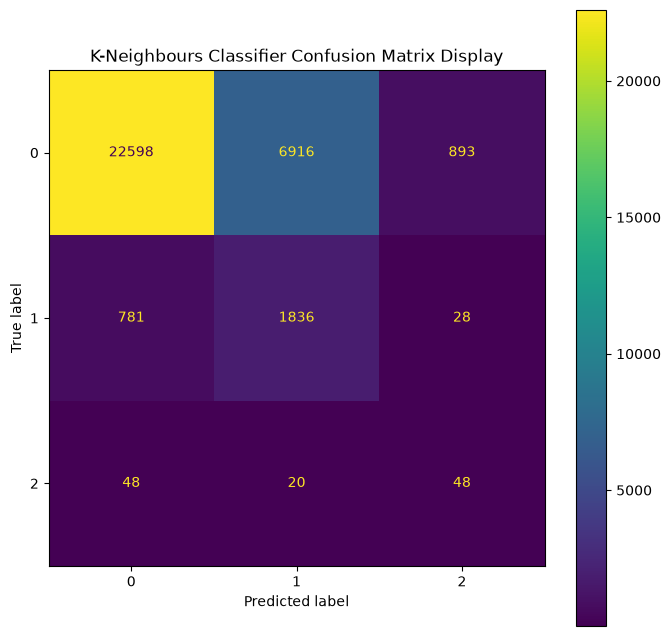

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


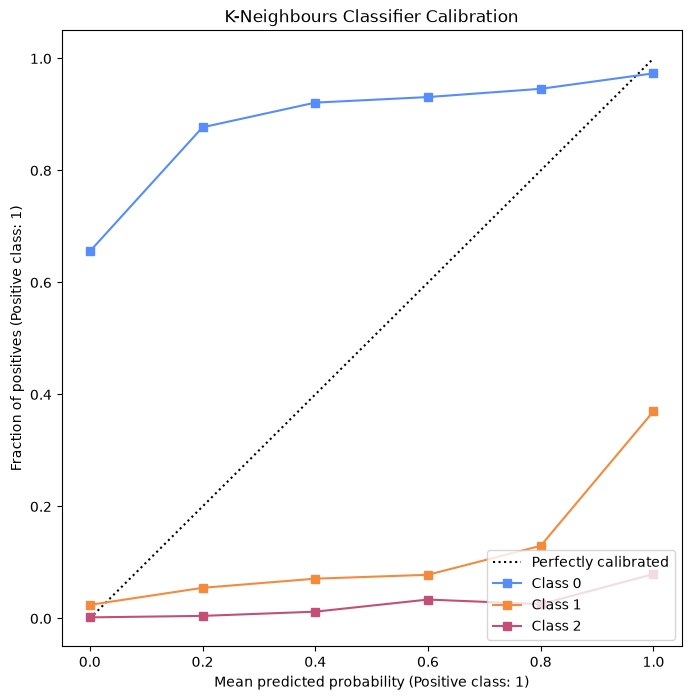

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


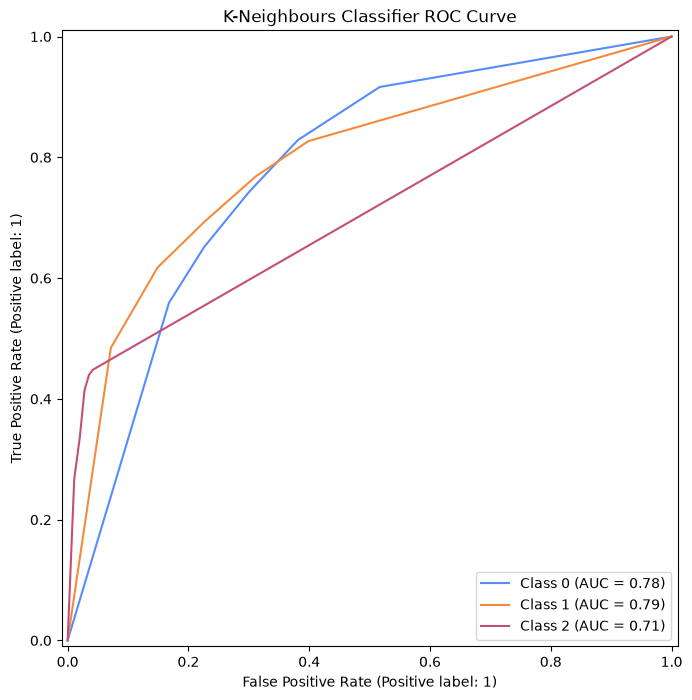

0 [1.  1.  0.2 ... 1.  1.  1. ]
1 [0.  0.  0.8 ... 0.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


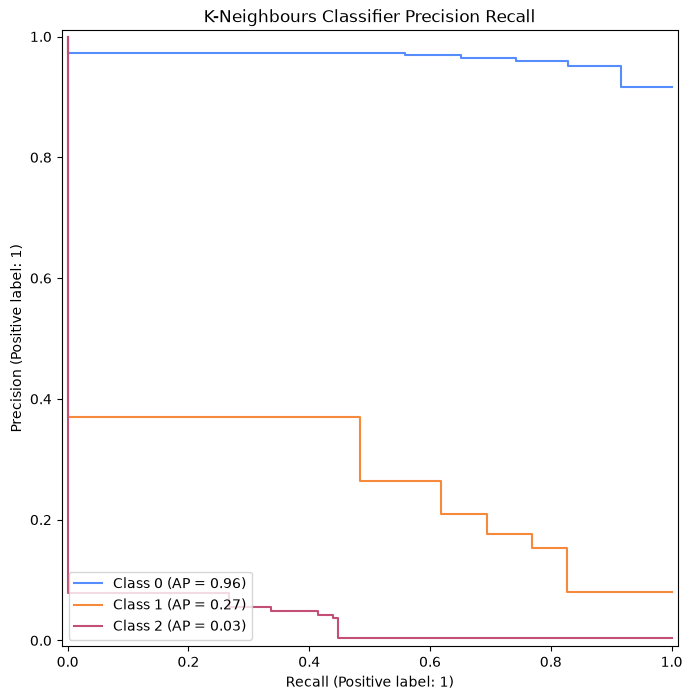

Macro Average Precision Score: 0.421


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during trans

Decision Tree Classifier Test Cross Val Accuracy: 0.7025 (0.0054)
Decision Tree Classifier Test Cross Val Balanced Accuracy: 0.5398 (0.0089)
Decision Tree Classifier Test Cross Val F1 Macro: 0.3740 (0.0034)
Decision Tree Classifier Test Cross Val ROC AUC: 0.7202 (0.0062)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.72      0.82     30407
           1       0.18      0.55      0.27      2645
           2       0.02      0.34      0.04       116

    accuracy                           0.71     33168
   macro avg       0.38      0.54      0.38     33168
weighted avg       0.88      0.71      0.77     33168

Confusion Matrix
[[21971  6806  1630]
 [ 1118  1466    61]
 [   61    15    40]]


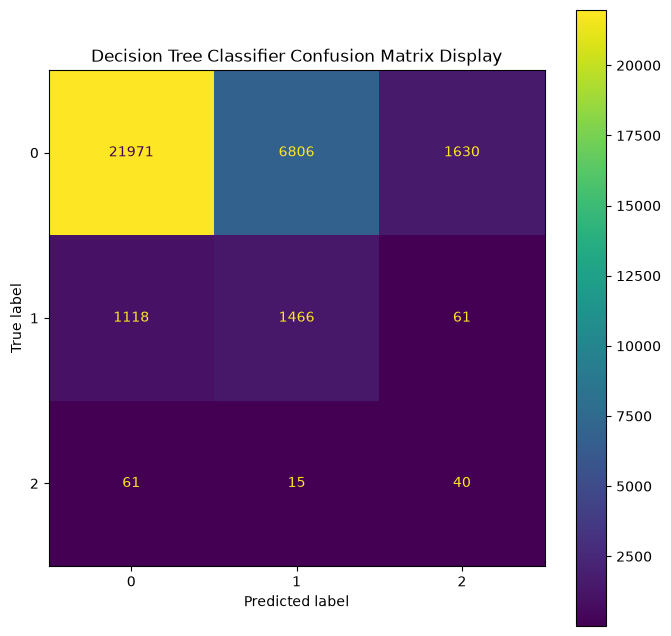

0 [0.23 0.83 0.58 ... 0.82 0.57 0.35]
1 [0.77 0.17 0.42 ... 0.18 0.43 0.65]
2 [0. 0. 0. ... 0. 0. 0.]


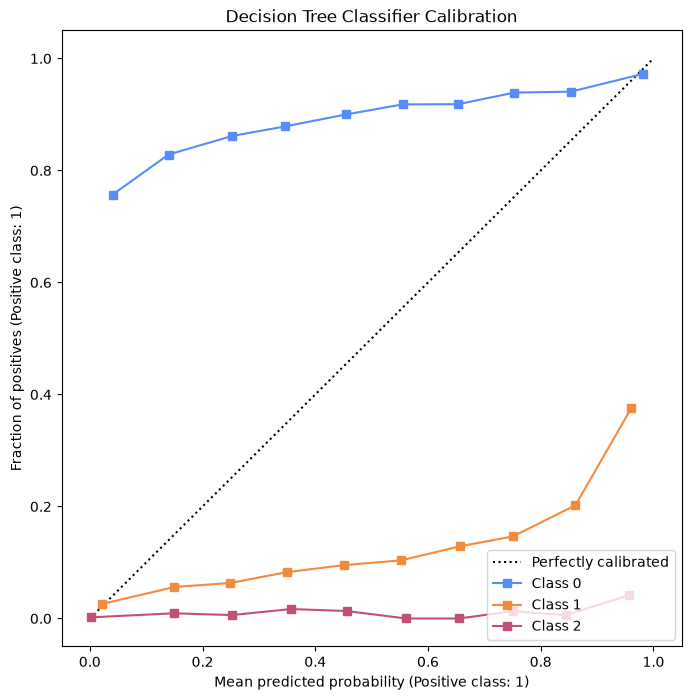

0 [0.23 0.83 0.58 ... 0.82 0.57 0.35]
1 [0.77 0.17 0.42 ... 0.18 0.43 0.65]
2 [0. 0. 0. ... 0. 0. 0.]


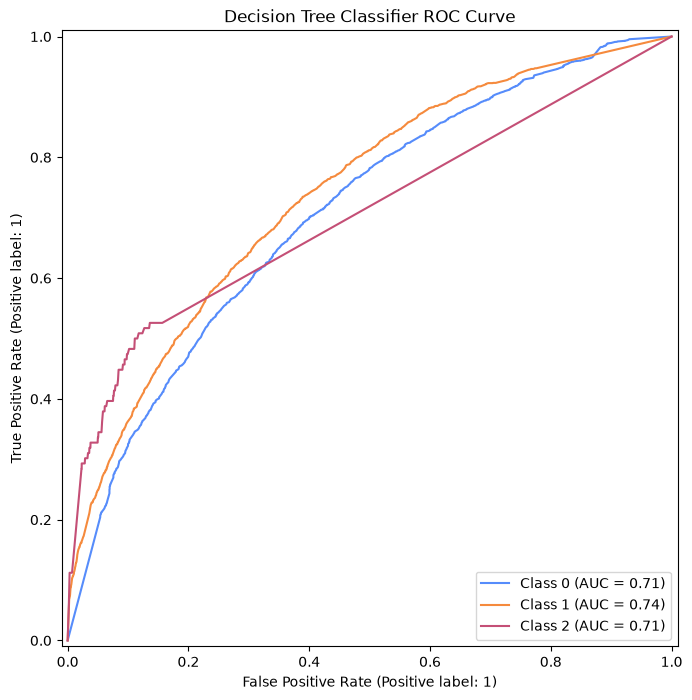

0 [0.23 0.83 0.58 ... 0.82 0.57 0.35]
1 [0.77 0.17 0.42 ... 0.18 0.43 0.65]
2 [0. 0. 0. ... 0. 0. 0.]


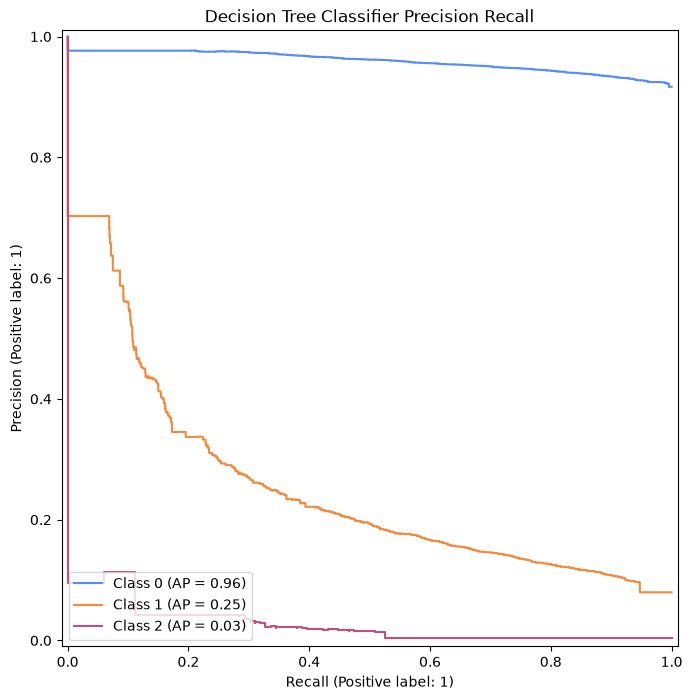

Macro Average Precision Score: 0.412


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarni

Linear SVC Test Cross Val Accuracy: 0.2629 (0.0140)
Linear SVC Test Cross Val Balanced Accuracy: 0.6133 (0.0037)
Linear SVC Test Cross Val F1 Macro: 0.1971 (0.0082)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.95      0.18      0.31     30407
           1       0.12      0.74      0.20      2645
           2       0.01      0.90      0.02       116

    accuracy                           0.23     33168
   macro avg       0.36      0.61      0.18     33168
weighted avg       0.88      0.23      0.30     33168

Confusion Matrix
[[ 5609 14541 10257]
 [  266  1960   419]
 [    4     8   104]]


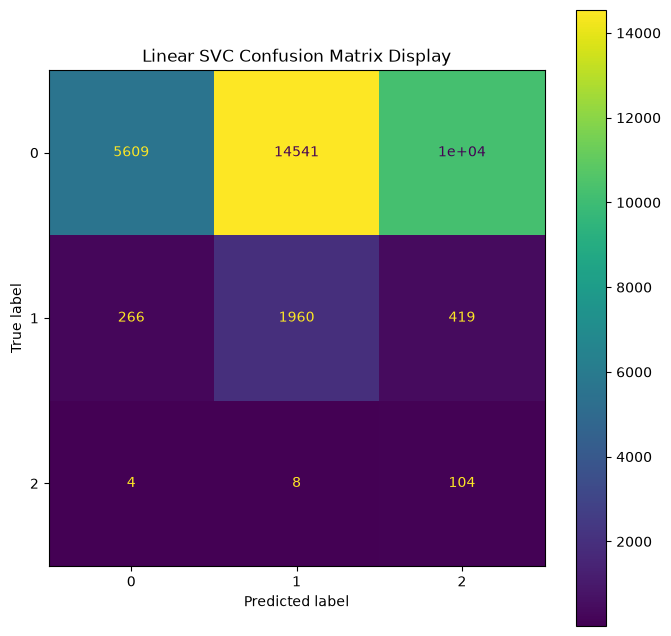

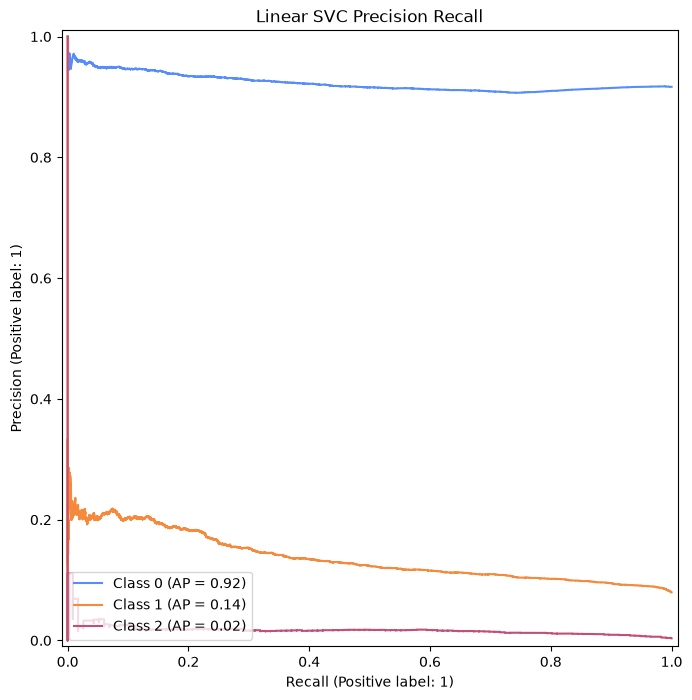

Macro Average Precision Score: 0.359


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during trans

Linear Discriminant Analysis Test Cross Val Accuracy: 0.4878 (0.0069)
Linear Discriminant Analysis Test Cross Val Balanced Accuracy: 0.6445 (0.0199)
Linear Discriminant Analysis Test Cross Val F1 Macro: 0.3037 (0.0047)
Linear Discriminant Analysis Test Cross Val ROC AUC: 0.7471 (0.0127)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.48      0.64     30407
           1       0.16      0.63      0.26      2645
           2       0.01      0.78      0.02       116

    accuracy                           0.49     33168
   macro avg       0.38      0.63      0.31     33168
weighted avg       0.89      0.49      0.61     33168

Confusion Matrix
[[14638  8723  7046]
 [  697  1663   285]
 [   20     5    91]]


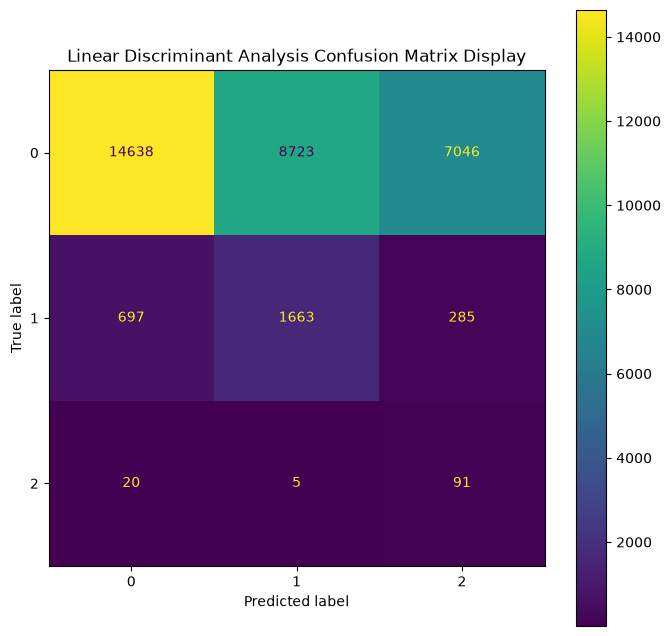

0 [0.64 0.52 0.61 ... 0.13 0.14 0.23]
1 [0.35 0.08 0.31 ... 0.87 0.86 0.74]
2 [0.01 0.41 0.08 ... 0.   0.   0.03]


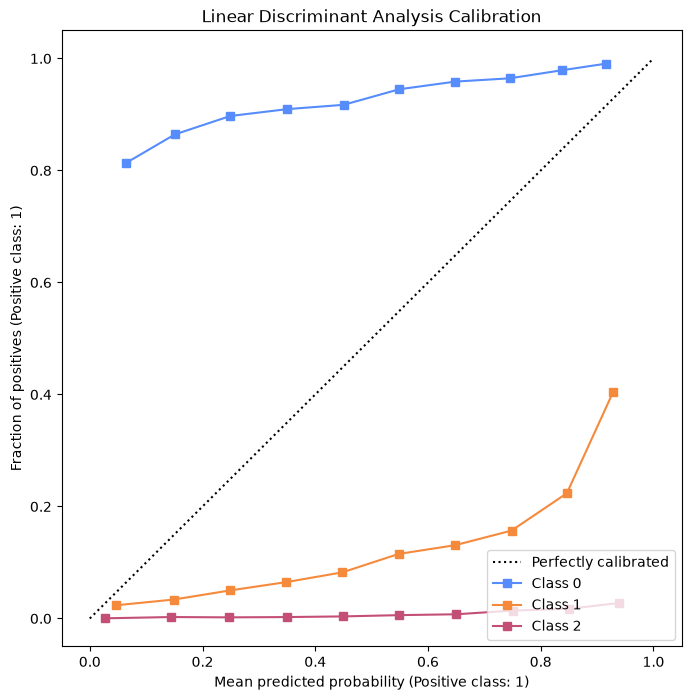

0 [0.64 0.52 0.61 ... 0.13 0.14 0.23]
1 [0.35 0.08 0.31 ... 0.87 0.86 0.74]
2 [0.01 0.41 0.08 ... 0.   0.   0.03]


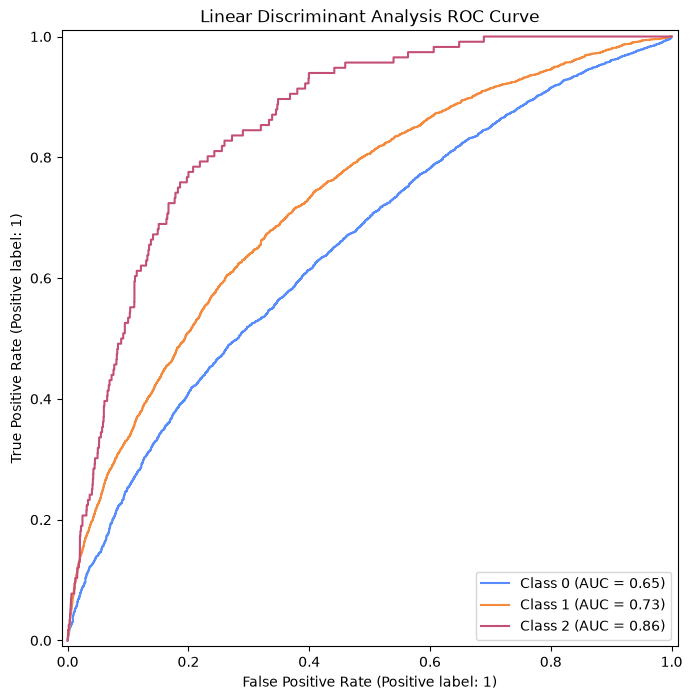

0 [0.64 0.52 0.61 ... 0.13 0.14 0.23]
1 [0.35 0.08 0.31 ... 0.87 0.86 0.74]
2 [0.01 0.41 0.08 ... 0.   0.   0.03]


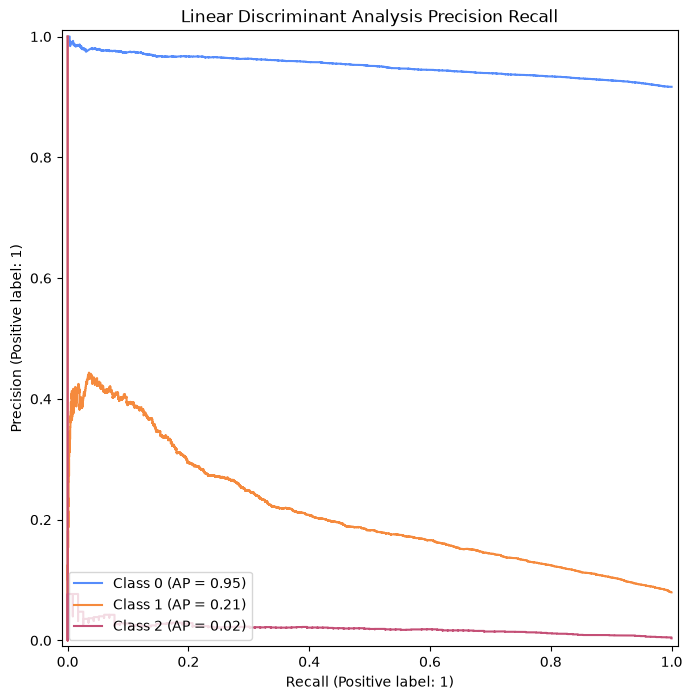

Macro Average Precision Score: 0.394


[Pipeline(memory=Memory(location=./model-cache/joblib),
          steps=[('continuous_data_transforms',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('box_cox',
                                                   PowerTransformer(method='box-cox',
                                                                    standardize=False),
                                                   [])],
                                    verbose_feature_names_out=False)),
                 ('drop_columns_transform',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('drop', 'drop',
                                                   ('E...
                                                                    VarianceThreshold()),
                                                                   ('recursive_feature_selection',
                                                    

In [14]:
primary_build_model_pipeline = _get_primary_build_model_pipeline()
primary_pipelines = run_model_pipeline(primary_build_model_pipeline, primary_x_train, primary_y_train, primary_x_test,
                                       primary_y_test)

primary_pipelines

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11349.95it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

K-Neighbours Bagging Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                   verbose_feature_names_out=False)),
                ('target_resamplin

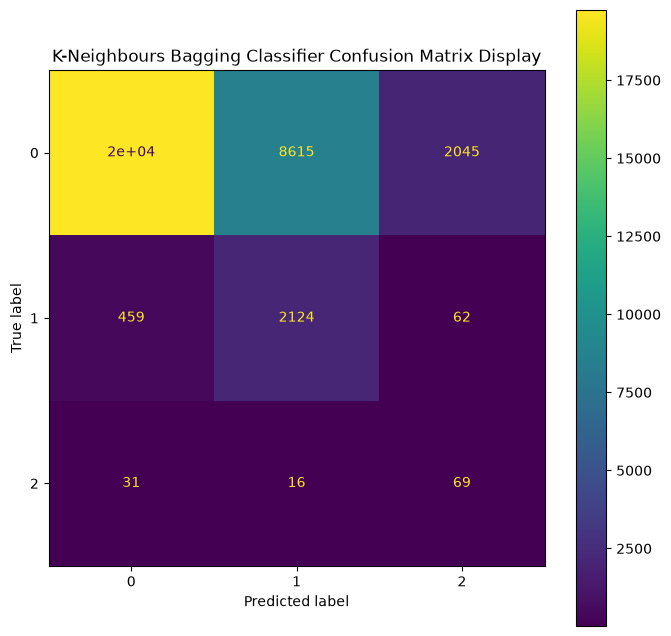

0 [1.   1.   0.12 ... 0.63 0.73 0.56]
1 [0.   0.   0.88 ... 0.37 0.27 0.44]
2 [0. 0. 0. ... 0. 0. 0.]


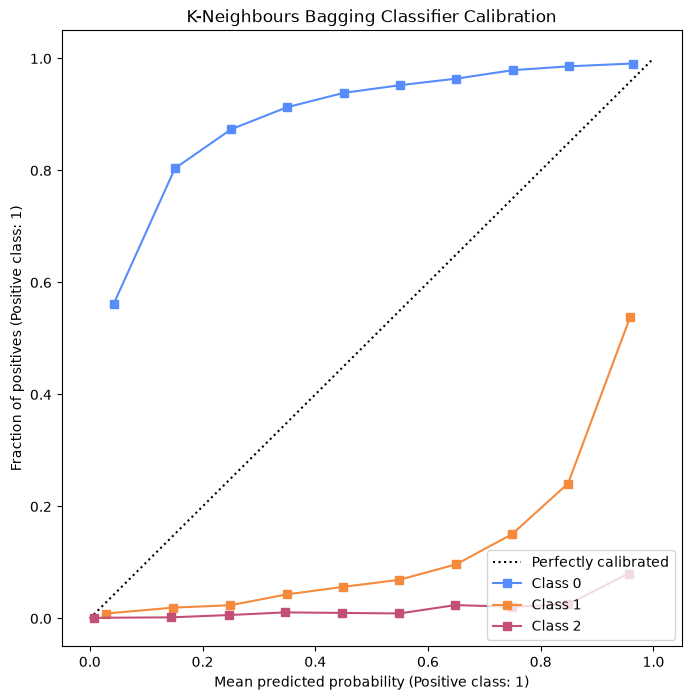

0 [1.   1.   0.12 ... 0.63 0.73 0.56]
1 [0.   0.   0.88 ... 0.37 0.27 0.44]
2 [0. 0. 0. ... 0. 0. 0.]


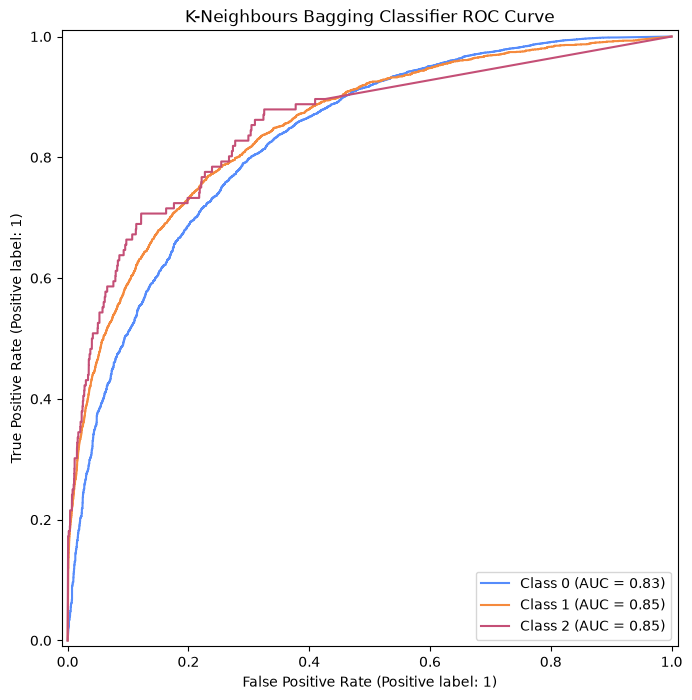

0 [1.   1.   0.12 ... 0.63 0.73 0.56]
1 [0.   0.   0.88 ... 0.37 0.27 0.44]
2 [0. 0. 0. ... 0. 0. 0.]


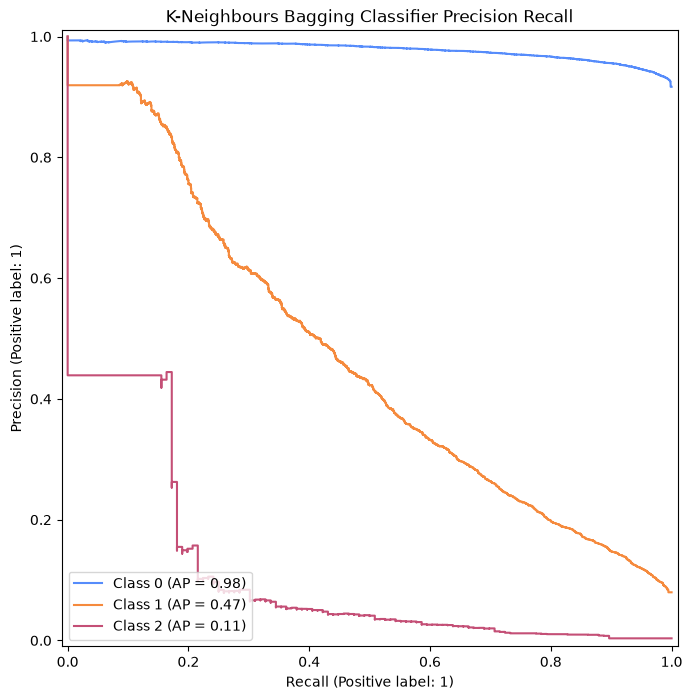

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [15]:
gc.collect()
torch.cuda.empty_cache()

primary_kneighbours_bagging_classifier_pipeline = _get_primary_build_model_pipeline()
primary_pipeline = run_kneighbours_bagging_classifier_pipeline(primary_kneighbours_bagging_classifier_pipeline,
                                                               primary_x_train,
                                                               primary_y_train,
                                                               primary_x_test,
                                                               primary_y_test)

primary_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6909.34it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).

Random Forest Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                                  slice(None, None, None))],
                                  

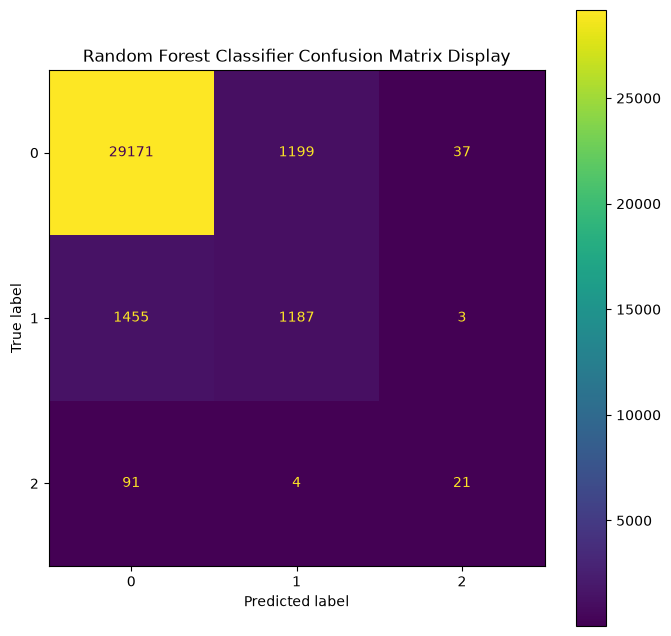

0 [0.97 0.97 0.73 ... 0.88 0.85 0.63]
1 [0.03 0.02 0.27 ... 0.12 0.15 0.36]
2 [0.   0.01 0.   ... 0.   0.   0.01]


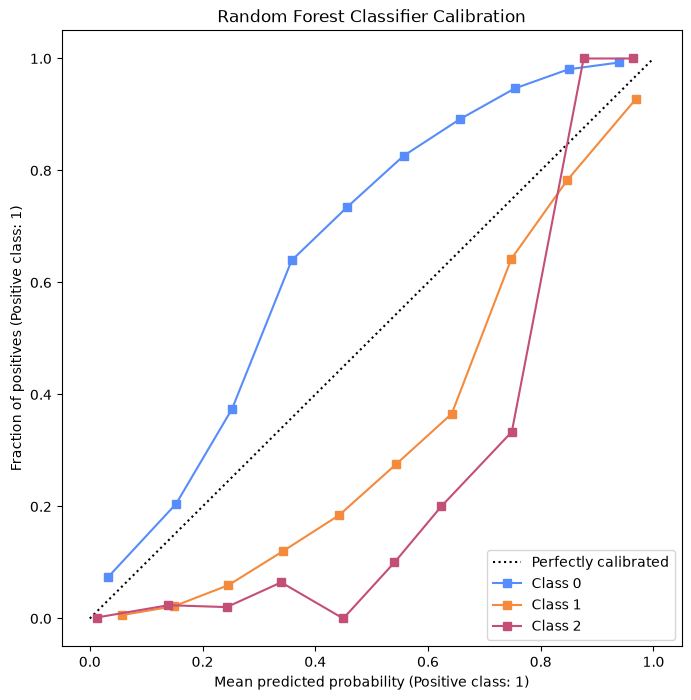

0 [0.97 0.97 0.73 ... 0.88 0.85 0.63]
1 [0.03 0.02 0.27 ... 0.12 0.15 0.36]
2 [0.   0.01 0.   ... 0.   0.   0.01]


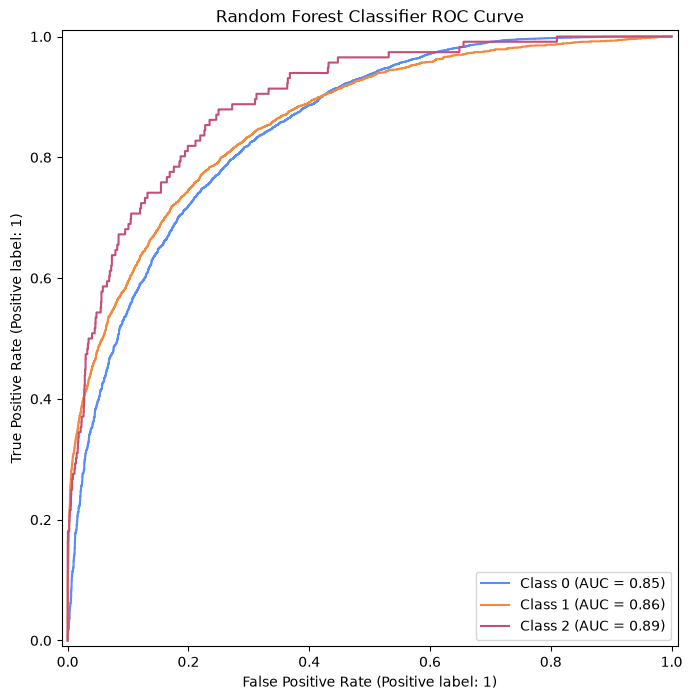

0 [0.97 0.97 0.73 ... 0.88 0.85 0.63]
1 [0.03 0.02 0.27 ... 0.12 0.15 0.36]
2 [0.   0.01 0.   ... 0.   0.   0.01]


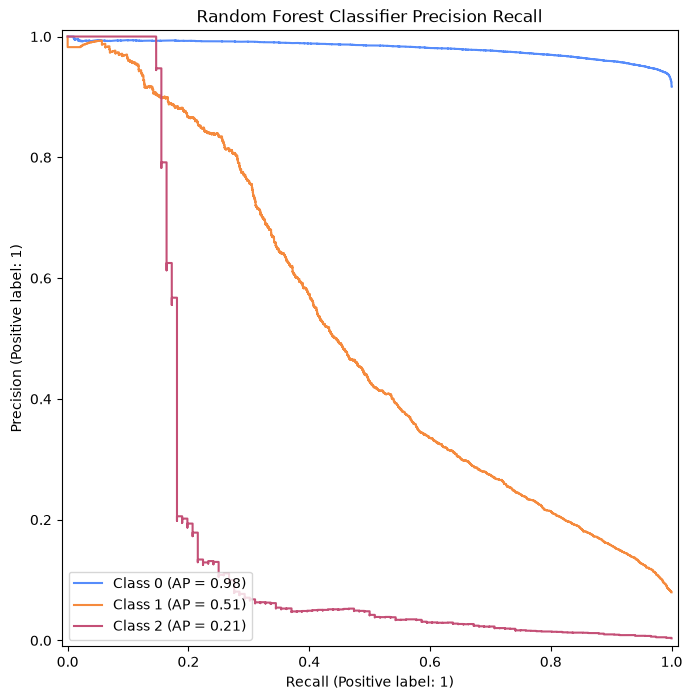

NameError: name 'physical_pipeline' is not defined

In [18]:
gc.collect()
torch.cuda.empty_cache()

primary_random_forest_classifier_pipeline = _get_primary_build_model_pipeline()
primary_pipeline = run_random_forest_pipeline(primary_random_forest_classifier_pipeline, primary_x_train,
                                              primary_y_train,
                                              primary_x_test,
                                              primary_y_test)

primary_pipeline

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 14682.34it/s]
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500)

ADA Boost Decision Tree Classifier Best Estimator: Pipeline(steps=[('continuous_data_transforms',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('box_cox',
                                                  PowerTransformer(method='box-cox',
                                                                   standardize=False),
                                                  [])],
                                   verbose_feature_names_out=False)),
                ('drop_columns_transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('drop', 'drop',
                                                  ('Entry Date Year Of '
                                                   'Transfer',
                                                   'Entry Date Quarter Of...
                                                                                                    m

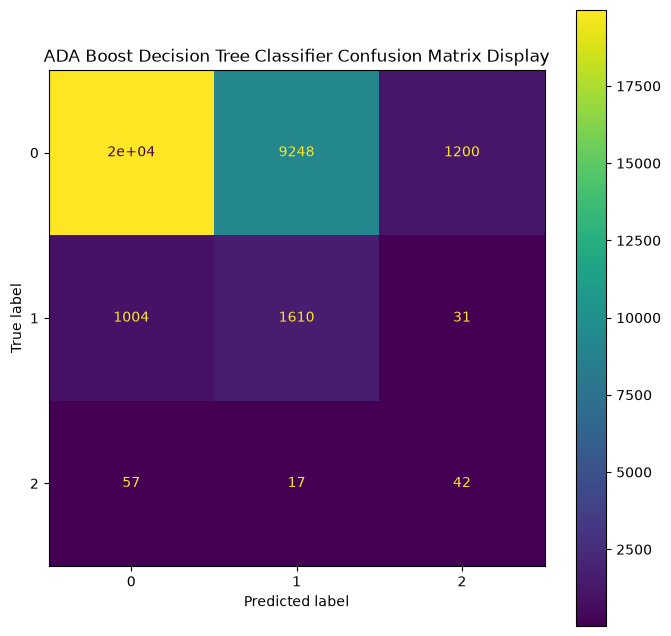

0 [0.35 0.37 0.36 ... 0.35 0.36 0.36]
1 [0.36 0.31 0.36 ... 0.36 0.37 0.35]
2 [0.29 0.32 0.29 ... 0.29 0.27 0.3 ]


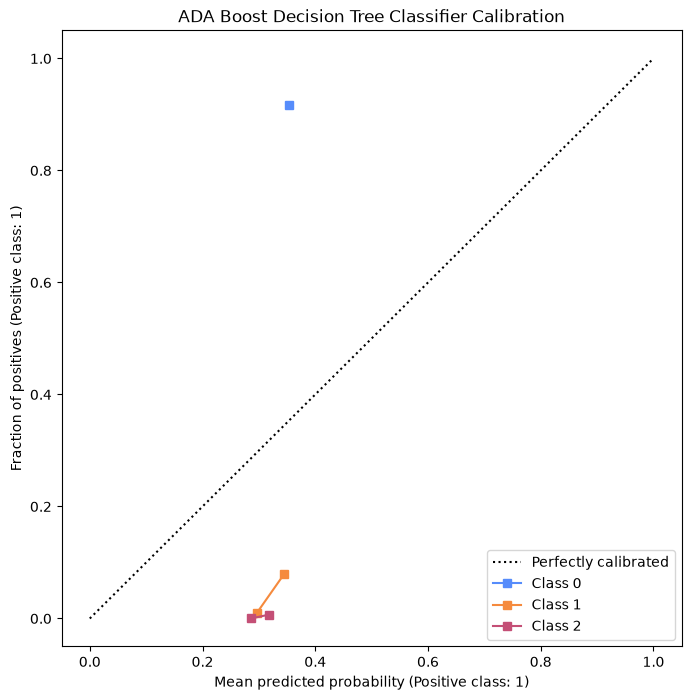

0 [0.35 0.37 0.36 ... 0.35 0.36 0.36]
1 [0.36 0.31 0.36 ... 0.36 0.37 0.35]
2 [0.29 0.32 0.29 ... 0.29 0.27 0.3 ]


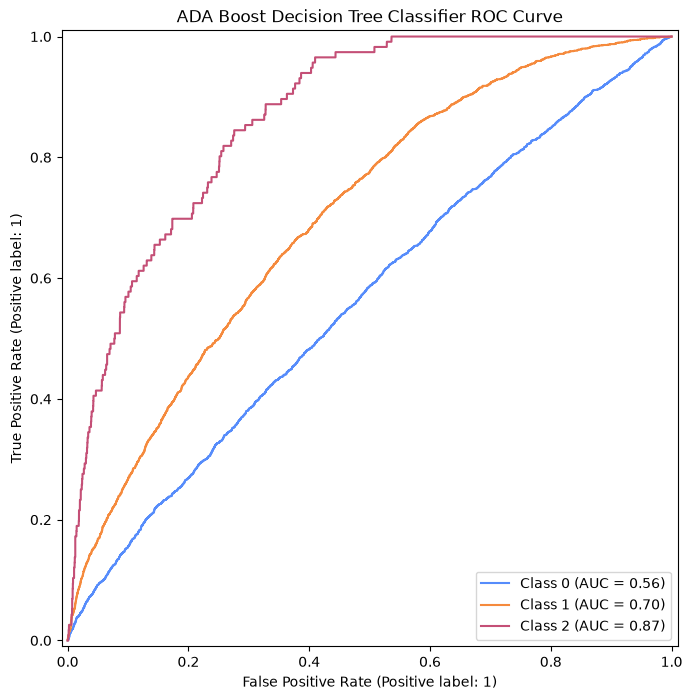

0 [0.35 0.37 0.36 ... 0.35 0.36 0.36]
1 [0.36 0.31 0.36 ... 0.36 0.37 0.35]
2 [0.29 0.32 0.29 ... 0.29 0.27 0.3 ]


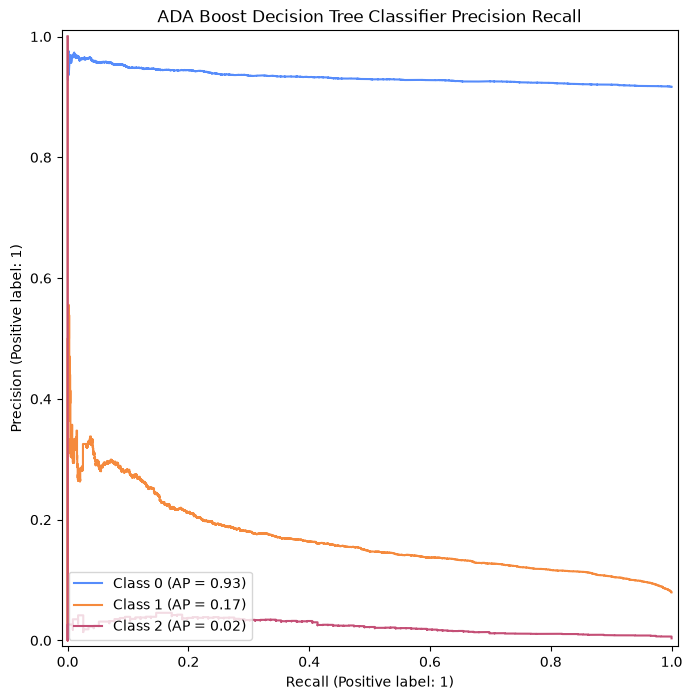

,steps,"[('continuous_data_transforms', ...), ('drop_columns_transform', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('box_cox', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more 

In [19]:
gc.collect()
torch.cuda.empty_cache()

primary_adaboost_decision_tree_pipeline = _get_primary_build_model_pipeline()
physical_pipeline = run_adaboost_decision_tree_pipeline(primary_adaboost_decision_tree_pipeline,
                                                        primary_x_train,
                                                        primary_y_train,
                                                        primary_x_test,
                                                        primary_y_test)

physical_pipeline

PermutationExplainer explainer: 51it [3:26:33, 247.86s/it]                          

SHAP explanation for class: Approve


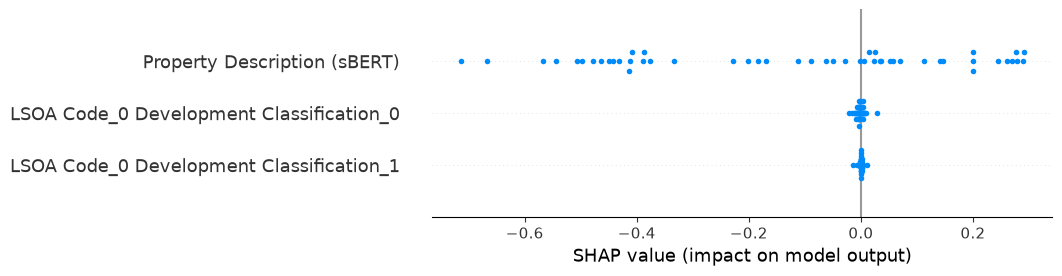

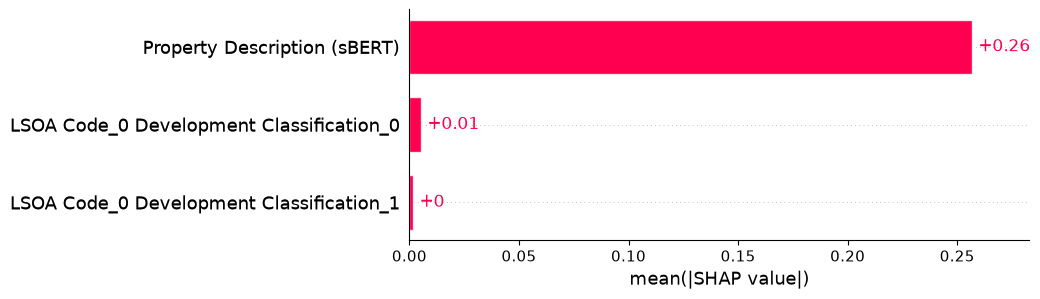

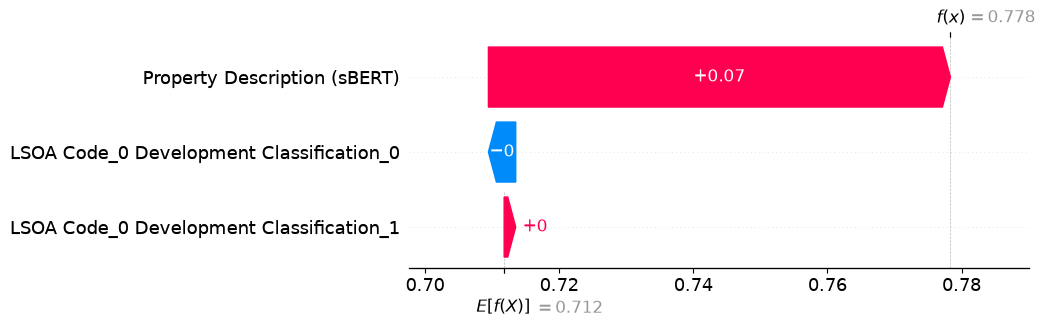

SHAP explanation for class: Refuse


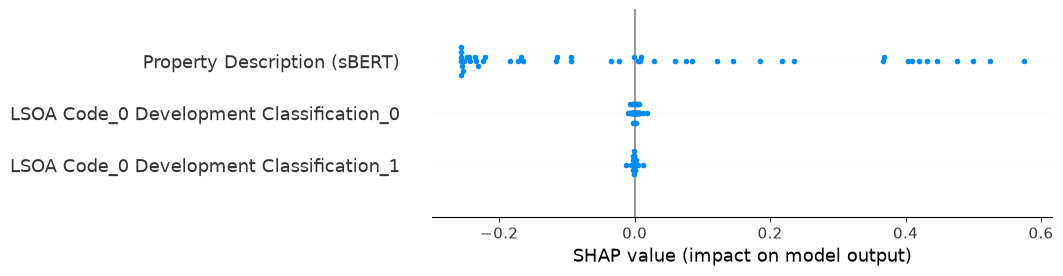

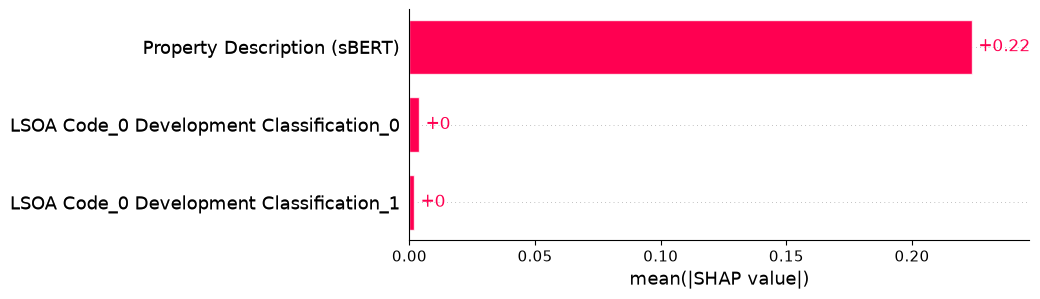

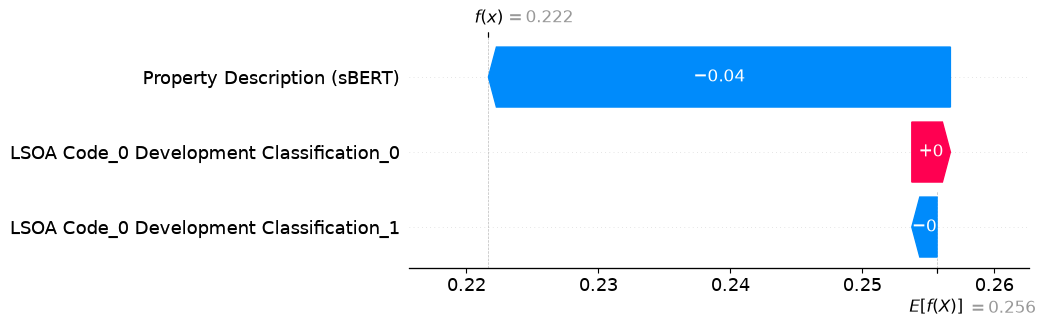

SHAP explanation for class: Split


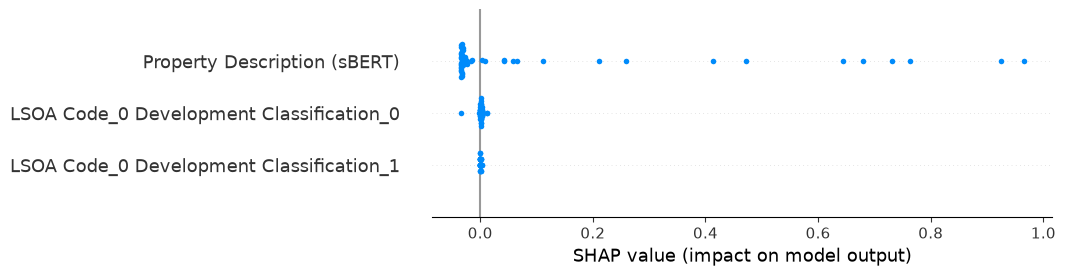

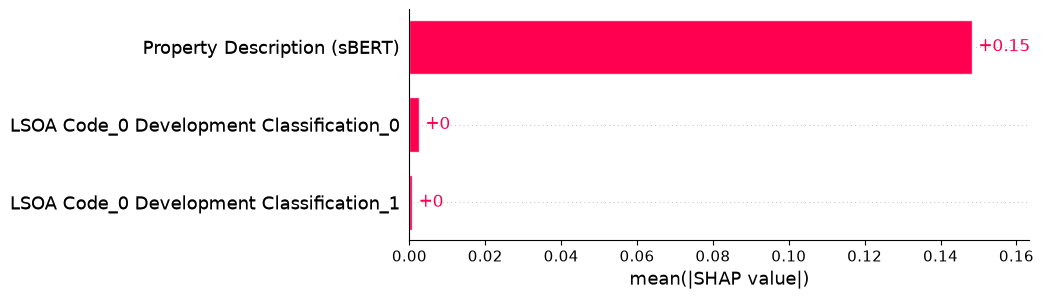

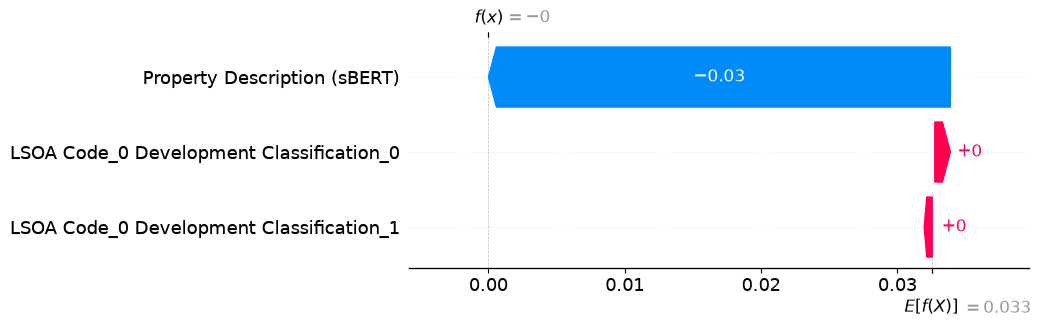

In [22]:
run_shap_analysis(k_neighbours_estimator.best_estimator_, primary_x_train, primary_x_test)

                 total  errors  error_rate  error_rate_pct
confidence_band                                           
(0.499, 0.6]      6472    3030    0.468171       46.817058
(0.6, 0.7]        6195    2557    0.412752       41.275222
(0.7, 0.8]        6009    2175    0.361957       36.195706
(0.8, 0.9]        5882    1762    0.299558       29.955797
(0.9, 1.0]        7655    1250    0.163292       16.329197


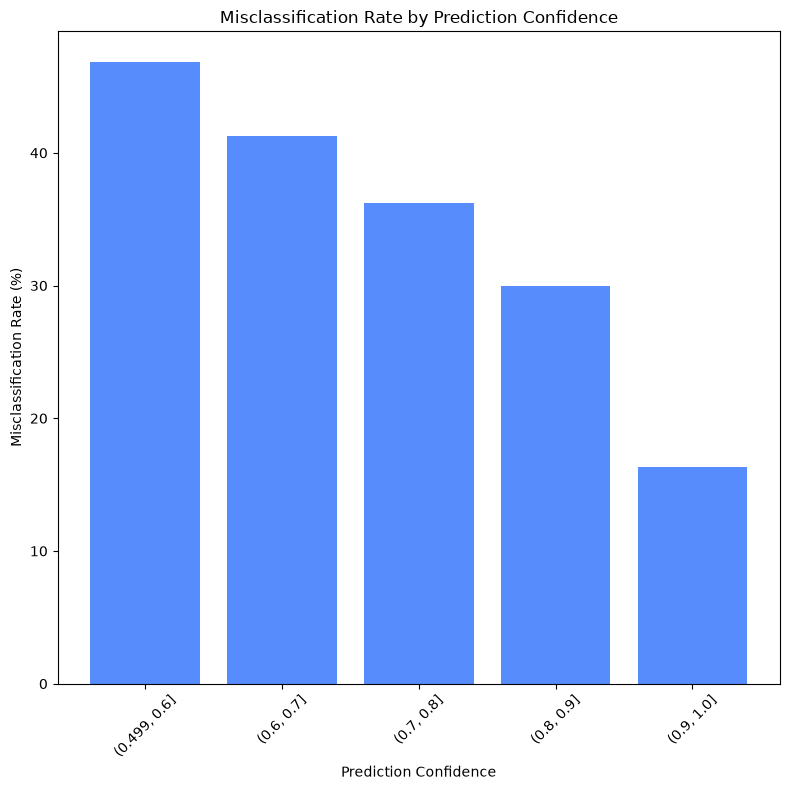

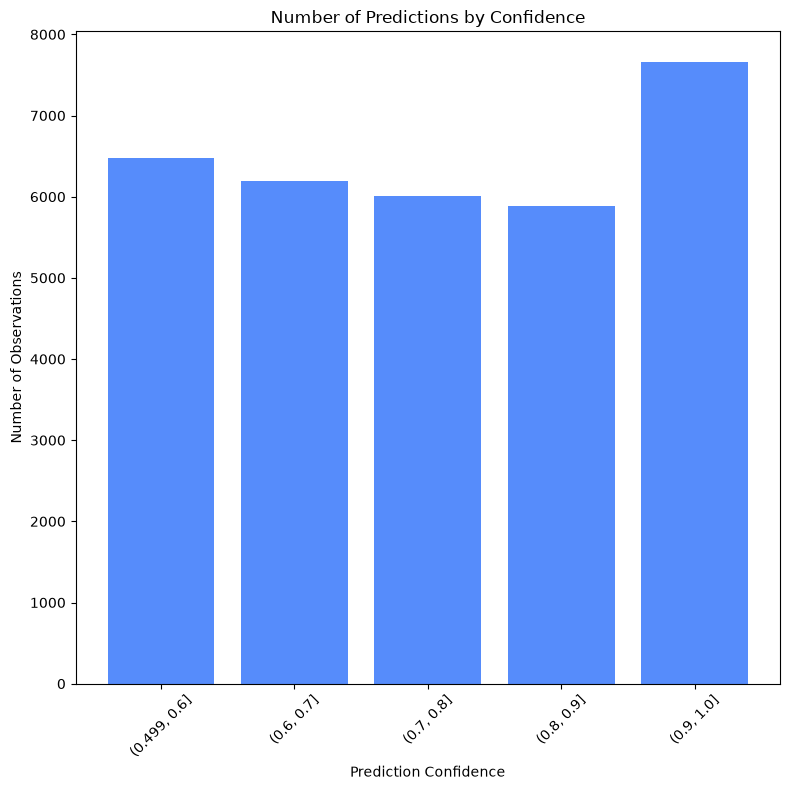

In [23]:
run_shap_inconsistency_analysis(k_neighbours_estimator.best_estimator_, primary_x_test, primary_y_test)